In [2]:
import numpy as np
import matplotlib.pyplot as plt

# PUNTO 1

## Desarrollo numérico de las ecuaciones de Lorenz

Las ecuaciones de Lorenz constituyen un sistema dinámico no lineal clásico que permite estudiar la aparición de comportamiento caótico a partir de reglas deterministas simples. Este tipo de formulación es consistente con el enfoque presentado en *Fractal River Basins* de Ignacio Rodríguez-Iturbe, donde los sistemas naturales se interpretan como estructuras complejas emergentes a partir de dinámicas locales simples.

El sistema de Lorenz está definido por el siguiente conjunto de ecuaciones diferenciales ordinarias:

$$
\frac{dx}{dt} = \sigma (y - x)
$$

$$
\frac{dy}{dt} = x(\rho - z) - y
$$

$$
\frac{dz}{dt} = xy - \beta z
$$

donde $\sigma$, $\rho$ y $\beta$ son parámetros positivos del sistema. Usualmente se emplean los valores $\sigma = 10$, $\rho = 28$ y $\beta = \frac{8}{3}$, para los cuales el sistema exhibe comportamiento caótico.

Dado que este sistema no posee una solución analítica cerrada, es necesario recurrir a métodos numéricos para aproximar su evolución en el tiempo. Para ello, se discretiza el dominio temporal en pasos de tamaño $\Delta t$, generando una sucesión de tiempos:

$$
t_0, t_1, t_2, \dots, t_n
$$

La derivada temporal puede aproximarse mediante diferencias finitas hacia adelante:

$$
\frac{dx}{dt} \approx \frac{x_{n+1} - x_n}{\Delta t}
$$

Aplicando esta aproximación a cada ecuación del sistema, se obtiene una versión discreta que permite calcular iterativamente la evolución del sistema:

$$
x_{n+1} = x_n + \Delta t \cdot \sigma (y_n - x_n)
$$

$$
y_{n+1} = y_n + \Delta t \cdot \left(x_n(\rho - z_n) - y_n\right)
$$

$$
z_{n+1} = z_n + \Delta t \cdot \left(x_n y_n - \beta z_n\right)
$$

Este esquema corresponde al método de Euler explícito, que transforma el sistema continuo en un sistema dinámico discreto. En términos vectoriales, puede escribirse como:

$$
\mathbf{X}_{n+1} = \mathbf{X}_n + \Delta t \cdot F(\mathbf{X}_n)
$$

donde $\mathbf{X}_n = (x_n, y_n, z_n)$ representa el estado del sistema en el tiempo $t_n$.

Desde la perspectiva de los sistemas complejos, este tipo de formulación es especialmente relevante, ya que permite interpretar la dinámica como un proceso iterativo generador de patrones. A pesar de la simplicidad de las ecuaciones, la evolución del sistema da lugar a estructuras altamente complejas en el espacio de fases, conocidas como atractores extraños.

Este comportamiento es análogo a lo observado en sistemas naturales como las redes de drenaje, donde reglas locales simples conducen a configuraciones espaciales complejas y organizadas. En este sentido, el sistema de Lorenz puede entenderse como un modelo conceptual que ilustra cómo emergen patrones complejos a partir de interacciones no lineales.

Además, el sistema presenta una alta sensibilidad a las condiciones iniciales, lo que implica que pequeñas perturbaciones en el estado inicial pueden generar trayectorias completamente diferentes en el largo plazo. Este fenómeno, conocido como caos determinista, es una característica fundamental en el estudio de sistemas naturales.

En consecuencia, el desarrollo numérico de las ecuaciones de Lorenz no solo permite obtener soluciones aproximadas, sino que constituye una herramienta clave para explorar la dinámica de sistemas complejos, analizar su estabilidad y comprender los mecanismos de autoorganización presentes en la naturaleza.

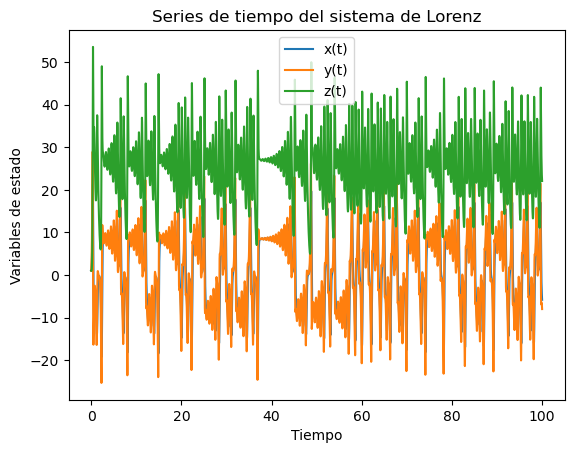

In [3]:
# -----------------------------
# 1. Parámetros del sistema
# -----------------------------
sigma = 10
rho = 28
beta = 8/3

# -----------------------------
# 2. Configuración temporal
# -----------------------------
dt = 0.01
n_steps = 10000

# -----------------------------
# 3. Inicialización
# -----------------------------
x = np.zeros(n_steps)
y = np.zeros(n_steps)
z = np.zeros(n_steps)

# Condiciones iniciales
x[0], y[0], z[0] = 1.0, 1.0, 1.0

# -----------------------------
# 4. Integración (Euler)
# -----------------------------
for i in range(n_steps - 1):
    x[i+1] = x[i] + dt * sigma * (y[i] - x[i])
    y[i+1] = y[i] + dt * (x[i]*(rho - z[i]) - y[i])
    z[i+1] = z[i] + dt * (x[i]*y[i] - beta*z[i])

# -----------------------------
# 5. Series de tiempo
# -----------------------------
t = np.arange(0, n_steps*dt, dt)

plt.figure()
plt.plot(t, x, label='x(t)')
plt.plot(t, y, label='y(t)')
plt.plot(t, z, label='z(t)')
plt.xlabel("Tiempo")
plt.ylabel("Variables de estado")
plt.title("Series de tiempo del sistema de Lorenz")
plt.legend()
plt.show()

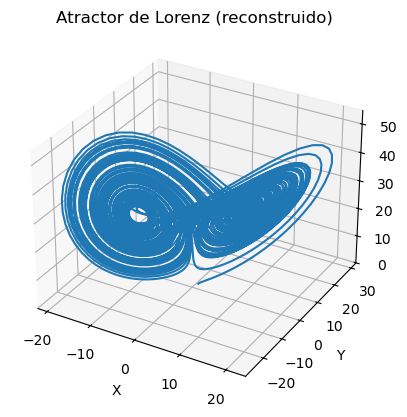

In [4]:
# -----------------------------
# 6. Reconstrucción del atractor
# -----------------------------
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot(x, y, z)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Atractor de Lorenz (reconstruido)")
plt.show()

### Comentario

El atractor reconstruido muestra una estructura característica en forma de *mariposa*, lo cual indica que el sistema evoluciona dentro de una región acotada del espacio de fases.

A pesar de estar gobernado por ecuaciones deterministas, la trayectoria no es periódica y presenta una alta sensibilidad a las condiciones iniciales, lo que constituye una evidencia clara de caos determinista.

La reconstrucción a partir de las tres series de tiempo permite recuperar completamente la dinámica del sistema, ya que las variables $x(t)$, $y(t)$ y $z(t)$ describen el estado del sistema en cada instante.

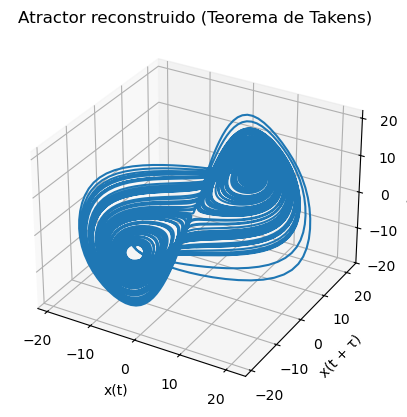

In [5]:
# -----------------------------
# 1. Simular sistema de Lorenz
# -----------------------------
sigma = 10
rho = 28
beta = 8/3

dt = 0.01
n_steps = 10000

x = np.zeros(n_steps)
y = np.zeros(n_steps)
z = np.zeros(n_steps)

# Condición inicial
x[0], y[0], z[0] = 1.0, 1.0, 1.0

# Integración (Euler)
for i in range(n_steps - 1):
    x[i+1] = x[i] + dt * sigma * (y[i] - x[i])
    y[i+1] = y[i] + dt * (x[i]*(rho - z[i]) - y[i])
    z[i+1] = z[i] + dt * (x[i]*y[i] - beta*z[i])

# -----------------------------
# 2. Seleccionar UNA serie
# -----------------------------
serie = x  # solo usamos x(t)

# -----------------------------
# 3. Parámetros de Takens
# -----------------------------
tau = 10       # retardo (delay)
m = 3          # dimensión de embedding

# -----------------------------
# 4. Reconstrucción (delay embedding)
# -----------------------------
N = len(serie) - (m - 1) * tau

X1 = serie[0:N]
X2 = serie[tau:N + tau]
X3 = serie[2*tau:N + 2*tau]

# -----------------------------
# 5. Visualización del atractor reconstruido
# -----------------------------
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot(X1, X2, X3)
ax.set_xlabel("x(t)")
ax.set_ylabel("x(t + τ)")
ax.set_zlabel("x(t + 2τ)")
ax.set_title("Atractor reconstruido (Teorema de Takens)")
plt.show()


### Comentario

Se ha reconstruido el atractor utilizando únicamente la serie de tiempo $x(t)$, aplicando el método de *embedding* con retardo (*delay embedding*).

Según el Teorema de Takens, es posible reconstruir un atractor equivalente (topológicamente) al original a partir de una sola variable observada.

La estructura obtenida reproduce la geometría del atractor de Lorenz, lo que evidencia que la dinámica del sistema está contenida en cada variable individual.

La elección de los parámetros $\tau$ (retardo) y $m$ (dimensión de embedding) es fundamental para obtener una reconstrucción adecuada del sistema dinámico.

# PUNTO 2 - 4

In [1]:
import ee
import geemap

ee.Authenticate(auth_mode='localhost')
ee.Initialize(project='hydro-496000')

In [64]:
basins = ee.FeatureCollection("WWF/HydroSHEDS/v1/Basins/hybas_8")

# Lista de PFAF_ID
pfaf_ids = [
    61567006
]

# Filtrar múltiples cuencas
subbasins = basins.filter(
    ee.Filter.inList("PFAF_ID", pfaf_ids)
)

# Geometría unificada
roi = subbasins.union().geometry()

In [65]:
# Convert FeatureCollection to GeoDataFrame
gdf = geemap.ee_to_gdf(subbasins)

In [66]:
roi_geom = ee.Feature(roi).geometry()

In [67]:
# DEM SRTM
dem = ee.Image("USGS/SRTMGL1_003").clip(roi)

Map = geemap.Map()
Map.centerObject(roi, 7)
# FeatureCollection
Map.addLayer(dem, {"min":0, "max":3000}, "DEM")
Map

Map(center=[4.655257304227624, -72.56657641551335], controls=(WidgetControl(options=['position', 'transparent_…

In [68]:
import os

In [69]:
# Carpeta de salida
output_folder = "tiles"
os.makedirs(output_folder, exist_ok=True)

# 🔹 Asegurar geometría correcta
roi_geom = roi.geometry() if hasattr(roi, "geometry") else roi

# 🔹 Crear grilla robusta
def create_grid(roi, nx=6, ny=6):

    bounds = roi.bounds()
    coords = ee.List(bounds.coordinates().get(0))

    xmin = ee.Number(ee.List(coords.get(0)).get(0))
    ymin = ee.Number(ee.List(coords.get(0)).get(1))
    xmax = ee.Number(ee.List(coords.get(2)).get(0))
    ymax = ee.Number(ee.List(coords.get(2)).get(1))

    dx = xmax.subtract(xmin).divide(nx)
    dy = ymax.subtract(ymin).divide(ny)

    cells = []

    for i in range(nx):
        for j in range(ny):

            x1 = xmin.add(dx.multiply(i))
            x2 = xmin.add(dx.multiply(i + 1))
            y1 = ymin.add(dy.multiply(j))
            y2 = ymin.add(dy.multiply(j + 1))

            tile = ee.Geometry.Rectangle([x1, y1, x2, y2], proj=None, geodesic=False)
            cells.append(tile)

    return cells

# 🔹 Crear tiles
tiles = create_grid(roi_geom, nx=6, ny=6)

# 🔹 DEM seguro
dem_prepared = dem.unmask()

# 🔥 IMPORTANTE: NO reproject dentro de EE export
# dejar reproyección para raster final

# 🔹 Exportación
for i, tile in enumerate(tiles):

    filename = f"{output_folder}/DEM_tile_{i}.tif"
    print(f"Exportando tile {i}...")

    try:
        geemap.ee_export_image(
            dem_prepared.clip(tile),
            filename=filename,
            scale=30,
            region=tile,
            file_per_band=False
        )

    except Exception as e:
        print(f"❌ Error en tile {i}: {e}")

Exportando tile 0...
Generating URL ...
Please wait ...
Data downloaded to e:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7\tiles\DEM_tile_0.tif
Exportando tile 1...
Generating URL ...
Please wait ...
Data downloaded to e:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7\tiles\DEM_tile_1.tif
Exportando tile 2...
Generating URL ...
Please wait ...
Data downloaded to e:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7\tiles\DEM_tile_2.tif
Exportando tile 3...
Generating URL ...
Please wait ...
Data downloaded to e:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7\tiles\DEM_tile_3.tif
Exportando tile 4...
Generating URL ...
Please wait ...
Data downloaded to e:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7\tiles\DEM_tile_4.tif
Exportando tile 5...
Generating URL ...
Please wait ...
Data downloaded to e:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7\tiles\DEM_tile_5.tif
Exportando tile 6...
Generating URL ...


In [70]:
import rasterio
from rasterio.merge import merge
from rasterio.warp import calculate_default_transform, reproject, Resampling
import glob

# -----------------------
# 1. Leer archivos
# -----------------------
files = glob.glob("tiles/*.tif")
srcs = [rasterio.open(f) for f in files]

# -----------------------
# 2. Merge (mosaico inicial)
# -----------------------
mosaic, transform = merge(srcs)

# -----------------------
# 3. Definir CRS destino (IMPORTANTE)
# -----------------------
dst_crs = srcs[0].crs  # o EPSG:3116 si quieres forzarlo

# -----------------------
# 4. Metadatos base
# -----------------------
meta = srcs[0].meta.copy()
meta.update({
    "height": mosaic.shape[1],
    "width": mosaic.shape[2],
    "transform": transform,
    "crs": dst_crs
})

# -----------------------
# 5. Guardar mosaico temporal
# -----------------------
with rasterio.open("dem_mosaic_raw.tif", "w", **meta) as dst:
    dst.write(mosaic)

# -----------------------
# 6. REPROYECCIÓN FINAL (CLAVE)
# -----------------------
dst_crs_final = "EPSG:3116"  # o el CRS del análisis hidrológico

with rasterio.open("dem_mosaic_raw.tif") as src:

    transform, width, height = calculate_default_transform(
        src.crs,
        dst_crs_final,
        src.width,
        src.height,
        *src.bounds
    )

    kwargs = src.meta.copy()
    kwargs.update({
        "crs": dst_crs_final,
        "transform": transform,
        "width": width,
        "height": height
    })

    with rasterio.open("dem_final.tif", "w", **kwargs) as dst:
        for i in range(1, src.count + 1):

            reproject(
                source=rasterio.band(src, i),
                destination=rasterio.band(dst, i),
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform,
                dst_crs=dst_crs_final,
                resampling=Resampling.bilinear
            )

In [71]:
gdf_3116 = gdf.to_crs(epsg=3116)

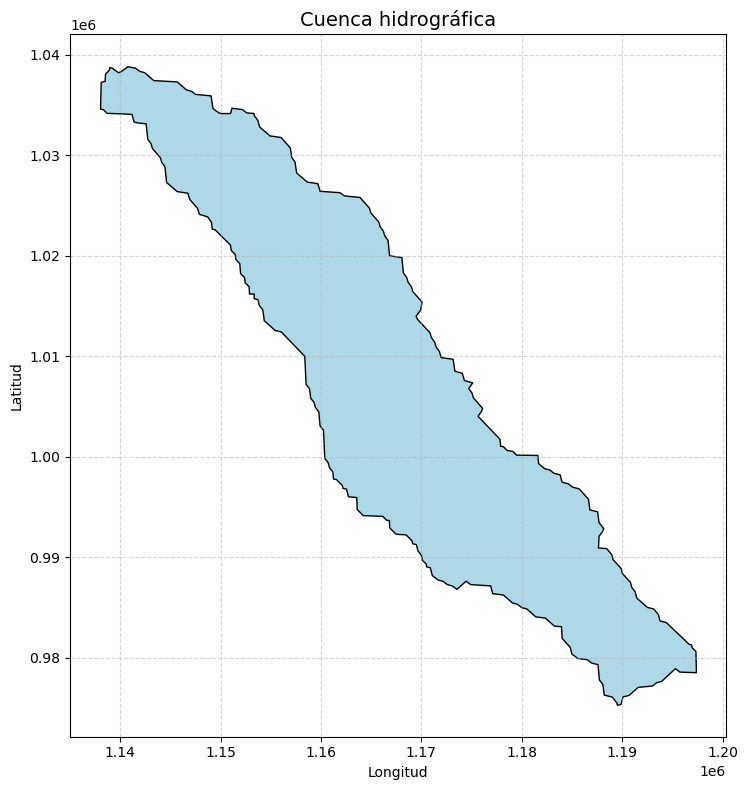

In [72]:
import matplotlib.pyplot as plt
# Crear figura
fig, ax = plt.subplots(figsize=(10, 8))

# Plot GeoDataFrame
gdf_3116.plot(
    ax=ax,
    edgecolor='black',
    facecolor='lightblue',
    linewidth=1
)

# Título
ax.set_title("Cuenca hidrográfica", fontsize=14)

# Etiquetas
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

# Grid
ax.grid(True, linestyle='--', alpha=0.5)

# Ajuste visual
plt.tight_layout()

plt.show()

In [73]:
import rasterio
from rasterio.mask import mask

with rasterio.open("dem_final.tif") as src:

    out_image, out_transform = mask(
        src,
        gdf_3116.geometry,
        crop=True
    )

    out_meta = src.meta.copy()

out_meta.update({
    "height": out_image.shape[1],
    "width": out_image.shape[2],
    "transform": out_transform
})

with rasterio.open(
    "dem_clip.tif",
    "w",
    **out_meta
) as dest:

    dest.write(out_image)

{'driver': 'GTiff', 'dtype': 'int16', 'nodata': -32768.0, 'width': 1988, 'height': 2130, 'count': 1, 'crs': CRS.from_wkt('PROJCS["MAGNA-SIRGAS / Colombia Bogota zone",GEOGCS["MAGNA-SIRGAS",DATUM["Marco_Geocentrico_Nacional_de_Referencia",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6686"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4686"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",4.59620041666667],PARAMETER["central_meridian",-74.0775079166667],PARAMETER["scale_factor",1],PARAMETER["false_easting",1000000],PARAMETER["false_northing",1000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Northing",NORTH],AXIS["Easting",EAST],AUTHORITY["EPSG","3116"]]'), 'transform': Affine(29.857994475648525, 0.0, 1137985.0272304465,
       0.0, -29.857994475648525, 1038874.2523964888), 'blockxsize': 1988, 'blockysize': 2, 'tiled': False, 'interleave': 'band'

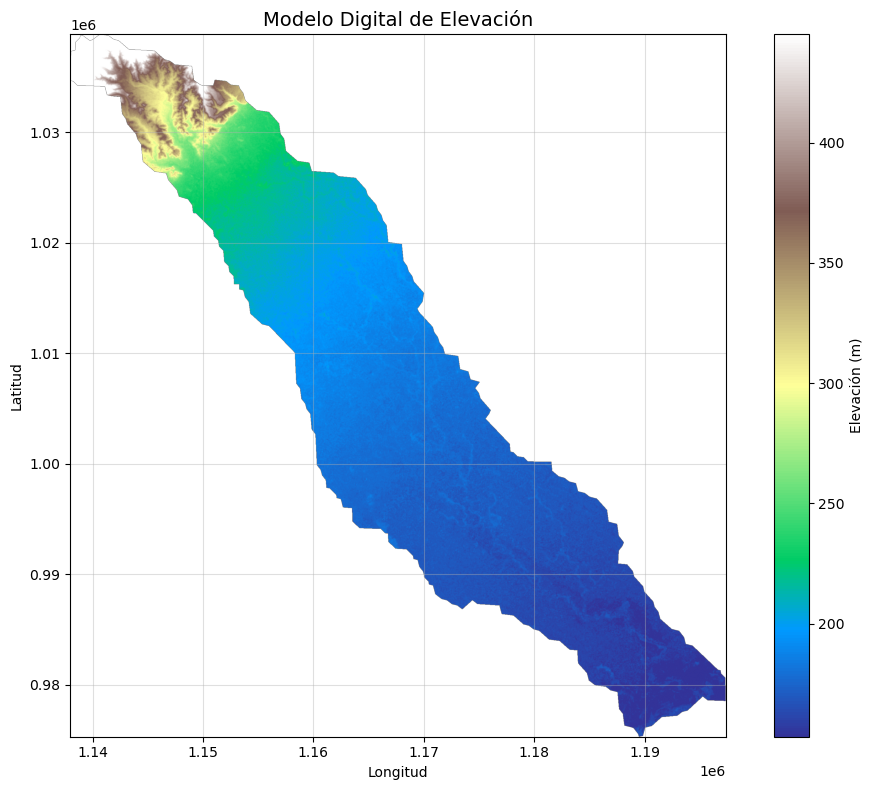

In [74]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import plotting_extent

# Leer DEM
with rasterio.open("dem_clip.tif") as src:
    
    dem = src.read(1)
    profile = src.profile
    
    # Obtener extensión espacial
    extent = plotting_extent(src)

# Mostrar metadata
print(profile)

# Reemplazar nodata
dem = np.where(dem <= -32768, np.nan, dem)

# Opcional: enmascarar valores bajos
dem_masked = np.where(dem >= 20, dem, np.nan)

# Crear figura
fig, ax = plt.subplots(figsize=(10, 8))

# Fondo transparente
fig.patch.set_alpha(0)

# Visualización DEM
img = ax.imshow(
    dem_masked,
    extent=extent,
    cmap='terrain',
    zorder=1,
    vmin=np.nanpercentile(dem_masked, 2),
    vmax=np.nanpercentile(dem_masked, 98)
)

# Barra de color
cbar = plt.colorbar(
    img,
    ax=ax,
    label='Elevación (m)'
)

# Grid
ax.grid(zorder=0, alpha=0.4)

# Títulos y ejes
ax.set_title('Modelo Digital de Elevación', fontsize=14)
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')

# Ajuste final
plt.tight_layout()

plt.show()

In [75]:
from whitebox.whitebox_tools import WhiteboxTools

wbt = WhiteboxTools()

print(wbt.version())

WhiteboxTools v2.4.0 (c) Dr. John Lindsay 2017-2023

WhiteboxTools is an advanced geospatial data analysis platform developed at
the University of Guelph's Geomorphometry and Hydrogeomatics Research 
Group (GHRG). See www.whiteboxgeo.com for more details.



In [76]:
from whitebox.whitebox_tools import WhiteboxTools

wbt = WhiteboxTools()

wbt.set_working_dir(
    r"E:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7"
)

In [77]:
wbt.breach_depressions_least_cost(
    dem="dem_clip.tif",
    output="dem_breach.tif",
    dist=50
)

.\whitebox_tools.exe --run="BreachDepressionsLeastCost" --wd="E:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7" --dem='dem_clip.tif' --output='dem_breach.tif' --dist='50' --min_dist --fill -v --compress_rasters=False

*****************************************
* Welcome to BreachDepressionsLeastCost *
* Powered by WhiteboxTools              *
* www.whiteboxgeo.com                   *
*****************************************
Reading data...
Finding pits: 0%
Finding pits: 1%
Finding pits: 2%
Finding pits: 3%
Finding pits: 4%
Finding pits: 5%
Finding pits: 6%
Finding pits: 7%
Finding pits: 8%
Finding pits: 9%
Finding pits: 10%
Finding pits: 11%
Finding pits: 12%
Finding pits: 13%
Finding pits: 14%
Finding pits: 15%
Finding pits: 16%
Finding pits: 17%
Finding pits: 18%
Finding pits: 19%
Finding pits: 20%
Finding pits: 21%
Finding pits: 22%
Finding pits: 23%
Finding pits: 24%
Finding pits: 25%
Finding pits: 26%
Finding pits: 27%
Finding pits: 28%
Finding pits: 29%
Finding pit

0

In [78]:
wbt.d8_pointer(
    r"dem_breach.tif",
    r"fdir.tif"
)

.\whitebox_tools.exe --run="D8Pointer" --wd="E:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7" --dem='dem_breach.tif' --output='fdir.tif' -v --compress_rasters=False

****************************
* Welcome to D8Pointer     *
* Powered by WhiteboxTools *
* www.whiteboxgeo.com      *
****************************
Reading data...
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progress: 40%
Progress: 41%
Progress: 42%
Progress: 43%
Progress: 44%
Progress: 45%
Progress: 46%
Progress:

0

In [79]:
wbt.d8_flow_accumulation(
    i="dem_breach.tif",
    output="acc.tif"
)

.\whitebox_tools.exe --run="D8FlowAccumulation" --wd="E:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7" --input='dem_breach.tif' --output='acc.tif' --out_type=cells -v --compress_rasters=False

*********************************
* Welcome to D8FlowAccumulation *
* Powered by WhiteboxTools      *
* www.whiteboxgeo.com           *
*********************************
Reading data...
Flow directions: 0%
Flow directions: 1%
Flow directions: 2%
Flow directions: 3%
Flow directions: 4%
Flow directions: 5%
Flow directions: 6%
Flow directions: 7%
Flow directions: 8%
Flow directions: 9%
Flow directions: 10%
Flow directions: 11%
Flow directions: 12%
Flow directions: 13%
Flow directions: 14%
Flow directions: 15%
Flow directions: 16%
Flow directions: 17%
Flow directions: 18%
Flow directions: 19%
Flow directions: 20%
Flow directions: 21%
Flow directions: 22%
Flow directions: 23%
Flow directions: 24%
Flow directions: 25%
Flow directions: 26%
Flow directions: 27%
Flow directions: 28%
Flow d

0

In [80]:
wbt.extract_streams(
    flow_accum="acc.tif",
    output="streams.tif",
    threshold=1000
)

.\whitebox_tools.exe --run="ExtractStreams" --wd="E:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7" --flow_accum='acc.tif' --output='streams.tif' --threshold='1000' -v --compress_rasters=False

*****************************
* Welcome to ExtractStreams *
* Powered by WhiteboxTools  *
* www.whiteboxgeo.com       *
*****************************
Reading data...
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progress: 40%
Progress: 41%
Progress: 42%
Progress: 43%
Progress: 44%
Progr

0

In [81]:
wbt.raster_streams_to_vector(
    streams="strahler.tif",
    d8_pntr="fdir.tif",
    output="streams.shp"
)

.\whitebox_tools.exe --run="RasterStreamsToVector" --wd="E:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7" --streams='strahler.tif' --d8_pntr='fdir.tif' --output='streams.shp' -v --compress_rasters=False

************************************
* Welcome to RasterStreamsToVector *
* Powered by WhiteboxTools         *
* www.whiteboxgeo.com              *
************************************
Reading pointer data...
Reading streams data...
thread 'main' panicked at whitebox-tools-app\src\main.rs:72:21:
The input files must have the same number of rows and columns and spatial extent.
note: run with `RUST_BACKTRACE=1` environment variable to display a backtrace


0

In [82]:
wbt.strahler_stream_order(
    d8_pntr="fdir.tif",
    streams="streams.tif",
    output="strahler.tif"
)

.\whitebox_tools.exe --run="StrahlerStreamOrder" --wd="E:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7" --d8_pntr='fdir.tif' --streams='streams.tif' --output='strahler.tif' -v --compress_rasters=False

**********************************
* Welcome to StrahlerStreamOrder *
* Powered by WhiteboxTools       *
* www.whiteboxgeo.com            *
**********************************
Reading pointer data...
Reading streams data...
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progress:

0

In [83]:
import rasterio
import numpy as np

with rasterio.open("strahler.tif") as src:
    st = src.read(1)

orders, counts = np.unique(
    st[st > 0],
    return_counts=True
)

print(dict(zip(orders, counts)))

{np.float32(1.0): np.int64(11055), np.float32(2.0): np.int64(6245), np.float32(3.0): np.int64(3142), np.float32(4.0): np.int64(1116), np.float32(5.0): np.int64(1033), np.float32(6.0): np.int64(1)}


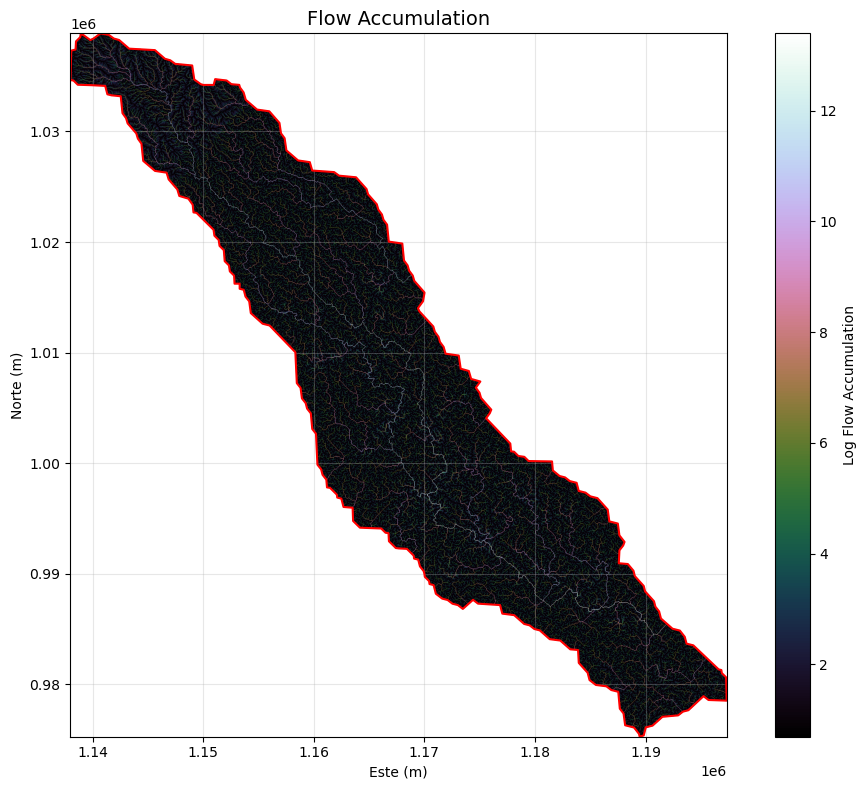

In [84]:
# -----------------------------
# Recortar raster con cuenca
# -----------------------------

with rasterio.open("acc.tif") as src:

    # Recorte usando geometría
    out_image, out_transform = mask(
        src,
        gdf_3116.geometry,
        crop=True
    )

    # Leer banda
    acc = out_image[0]

    # Reemplazar nodata
    acc = np.where(acc <= 0, np.nan, acc)

    # Extensión espacial
    extent = plotting_extent(
        acc,
        out_transform
    )

# -----------------------------
# Plot
# -----------------------------

fig, ax = plt.subplots(figsize=(10,8))

# Flow accumulation log
img = ax.imshow(
    np.log1p(acc),
    cmap="cubehelix",
    extent=extent,
    zorder=1
)

# Barra de color
cbar = plt.colorbar(
    img,
    ax=ax,
    label="Log Flow Accumulation"
)

# Límite cuenca
gdf_3116.boundary.plot(
    ax=ax,
    color="red",
    linewidth=1.5,
    zorder=2
)

# Título
ax.set_title("Flow Accumulation", fontsize=14)

# Etiquetas
ax.set_xlabel("Este (m)")
ax.set_ylabel("Norte (m)")

# Grid
ax.grid(alpha=0.3)

plt.tight_layout()

plt.show()

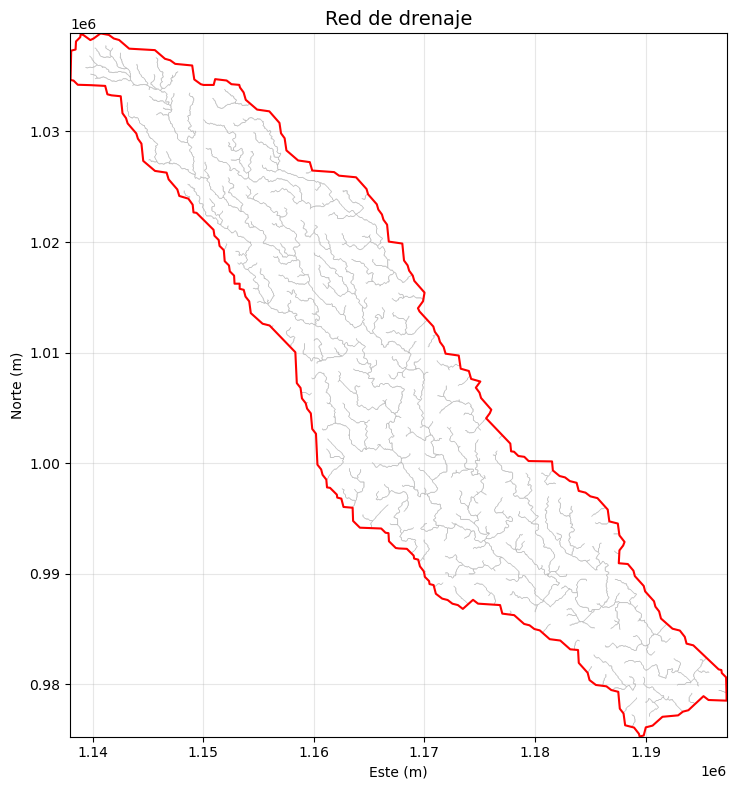

In [85]:
# -----------------------------
# Recortar raster con cuenca
# -----------------------------

with rasterio.open("streams.tif") as src:

    # Recorte usando geometría del gdf
    out_image, out_transform = mask(
        src,
        gdf_3116.geometry,
        crop=True
    )

    # Leer banda
    streams = out_image[0]

    # Reemplazar nodata
    streams = np.where(streams <= 0, np.nan, streams)

    # Extensión espacial
    extent = plotting_extent(
        streams,
        out_transform
    )

# -----------------------------
# Plot
# -----------------------------

fig, ax = plt.subplots(figsize=(10,8))

# Raster streams
img = ax.imshow(
    streams,
    cmap="Blues",
    extent=extent,
    zorder=1
)

# Borde de cuenca
gdf_3116.boundary.plot(
    ax=ax,
    color="red",
    linewidth=1.5,
    zorder=2
)

# Título
ax.set_title("Red de drenaje", fontsize=14)

# Etiquetas
ax.set_xlabel("Este (m)")
ax.set_ylabel("Norte (m)")

# Grid
ax.grid(alpha=0.3)

plt.tight_layout()

plt.show()

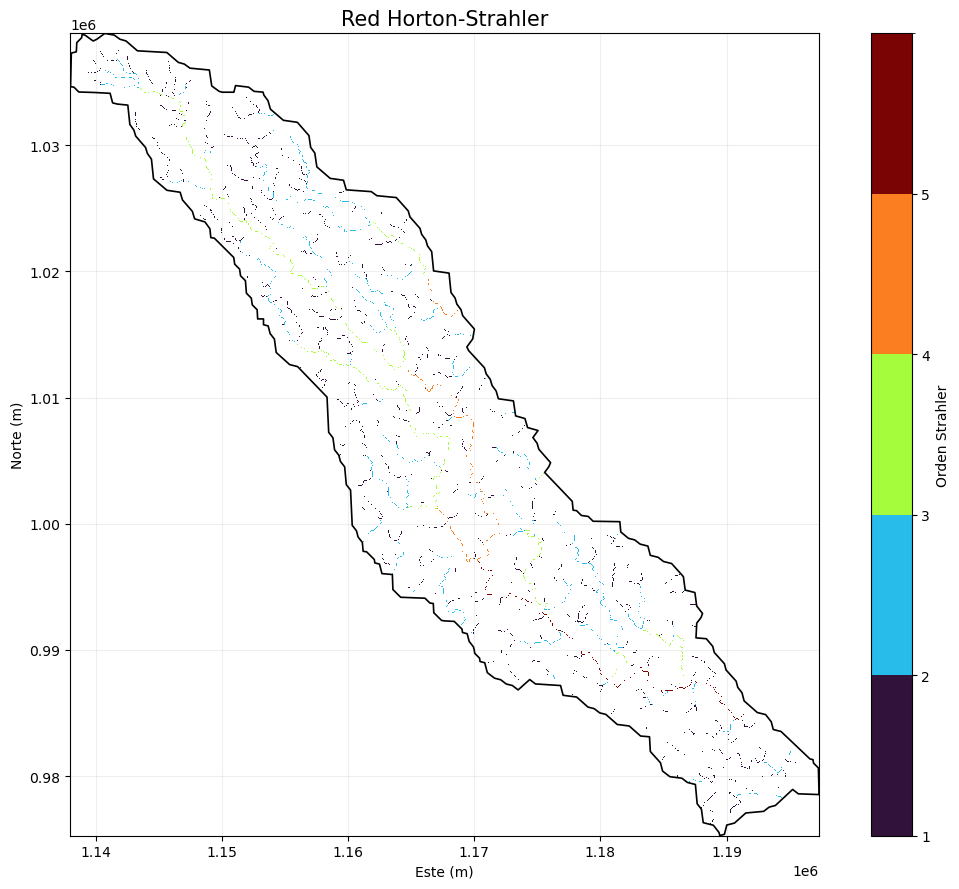

In [86]:
from matplotlib.colors import ListedColormap, BoundaryNorm

# -----------------------------
# Recorte
# -----------------------------

with rasterio.open("strahler.tif") as src:

    out_image, out_transform = mask(
        src,
        gdf_3116.geometry,
        crop=True
    )
    
    st = out_image[0]

    # Remover valores inválidos
    st = np.where(st <= 0, np.nan, st)

    extent = plotting_extent(
        st,
        out_transform
    )

# -----------------------------
# Detectar órdenes válidos
# -----------------------------

orders, counts = np.unique(
    st[~np.isnan(st)],
    return_counts=True
)

# Filtrar órdenes espurios
min_pixels = 10

valid_orders = orders[
    counts > min_pixels
].astype(int)

# Limpiar raster
st = np.where(
    np.isin(st, valid_orders),
    st,
    np.nan
)

# -----------------------------
# Colormap automático
# -----------------------------

# Puedes cambiar el cmap base
base_cmap = plt.cm.get_cmap("turbo", len(valid_orders))

colors = base_cmap(
    np.arange(len(valid_orders))
)

cmap = ListedColormap(colors)

# Límites automáticos
bounds = np.append(
    valid_orders,
    valid_orders[-1] + 1
)

norm = BoundaryNorm(
    bounds,
    cmap.N
)

# -----------------------------
# Plot
# -----------------------------

fig, ax = plt.subplots(figsize=(11, 9))

# Fondo blanco
ax.set_facecolor("white")

# Strahler
img = ax.imshow(
    st,
    cmap=cmap,
    norm=norm,
    extent=extent,
    interpolation="nearest",
    zorder=2
)

# Borde cuenca
gdf_3116.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.2,
    zorder=3
)

# Colorbar discreta automática
cbar = plt.colorbar(
    img,
    ax=ax,
    ticks=valid_orders
)

cbar.set_label("Orden Strahler")

# Título
ax.set_title(
    "Red Horton-Strahler",
    fontsize=15
)

# Etiquetas
ax.set_xlabel("Este (m)")
ax.set_ylabel("Norte (m)")

# Grid suave
ax.grid(alpha=0.2)

plt.tight_layout()

plt.show()

In [87]:
# Convert FeatureCollection to GeoDataFrame
gdf = geemap.ee_to_gdf(subbasins)

In [88]:
# Obtener órdenes y conteos
orders, counts = np.unique(
    st[st > 0],
    return_counts=True
)

# Mantener solo órdenes con más de X píxeles
min_pixels = 10

mask_valid = counts > min_pixels

# Filtrar órdenes y conteos
orders = orders[mask_valid].astype(int)
counts = counts[mask_valid]

print("Órdenes válidos:", orders)
print("Conteos válidos:", counts)

# Limpiar raster
st = np.where(
    np.isin(st, orders),
    st,
    np.nan
)

Órdenes válidos: [1 2 3 4 5]
Conteos válidos: [11055  6245  3142  1116  1033]


In [89]:
Rb = {}

for i in range(len(orders) - 1):

    orden = int(orders[i])

    # Ley de Horton:
    # Rb = N(w) / N(w+1)

    Rb[orden] = counts[i] / counts[i + 1]

print("Rb por orden:")
print(Rb)

# Rb promedio
Rb_mean = np.mean(list(Rb.values()))

print("\nRb promedio:")
print(Rb_mean)

Rb por orden:
{1: np.float64(1.7702161729383508), 2: np.float64(1.9875875238701464), 3: np.float64(2.815412186379928), 4: np.float64(1.080348499515973)}

Rb promedio:
1.9133910956760993


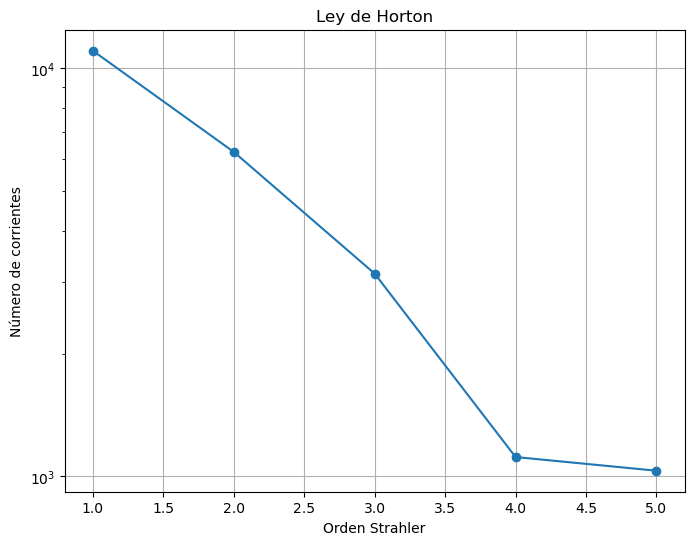

In [90]:
plt.figure(figsize=(8,6))

plt.plot(orders, counts, marker='o')

plt.yscale("log")

plt.xlabel("Orden Strahler")

plt.ylabel("Número de corrientes")

plt.title("Ley de Horton")

plt.grid(True)

plt.show()

In [91]:
from scipy.stats import linregress
import numpy as np

log_counts = np.log10(counts)

slope, intercept, r_value, p_value, std_err = linregress(
    orders,
    log_counts
)

print("R²:", r_value**2)

R²: 0.9590629341591153


In [92]:
import geopandas as gpd

streams_gdf = gpd.read_file("streams.shp")

In [93]:
streams_gdf = streams_gdf.set_crs(3116)

In [94]:
streams_gdf["length_m"] = (
    streams_gdf.geometry.length
)

In [95]:
print(streams_gdf.columns)

Index(['FID', 'STRM_VAL', 'geometry', 'length_m'], dtype='str')


In [96]:
mean_lengths = (
    streams_gdf
    .groupby("STRM_VAL")["length_m"]
    .mean()
)

print(mean_lengths)

STRM_VAL
1.0    345.508826
2.0    333.713305
3.0    248.068724
4.0    261.548355
5.0    240.111538
Name: length_m, dtype: float64


In [97]:
orders = mean_lengths.index.values

lengths = mean_lengths.values

RL = {}

for i in range(len(orders)-1):

    RL[int(orders[i])] = (
        lengths[i+1] / lengths[i]
    )

print(RL)

RL_mean = np.mean(list(RL.values()))

print("\nRL promedio:")
print(RL_mean)

{1: np.float64(0.9658604350636), 2: np.float64(0.7433588068183062), 3: np.float64(1.0543382917802726), 4: np.float64(0.9180387993081818)}

RL promedio:
0.9203990832425901


In [98]:
# -----------------------------
# Área por píxel
# -----------------------------

pixel_size = 30   # metros

pixel_area = pixel_size ** 2   # m²

# -----------------------------
# Área total por orden
# -----------------------------

areas = counts * pixel_area

print("\nÁreas por orden (m²):")
print(dict(zip(orders, areas)))

# -----------------------------
# Horton Area Ratio
# -----------------------------

RA = {}

for i in range(0, len(orders)):

    RA[int(orders[i])] = (
        areas[i] / areas[i - 1]
    )

print("\nRA por orden:")
print(RA)

# -----------------------------
# RA promedio
# -----------------------------

RA_mean = np.mean(
    list(RA.values())
)

print("\nRA promedio:")
print(RA_mean)


Áreas por orden (m²):
{np.float64(1.0): np.int64(9949500), np.float64(2.0): np.int64(5620500), np.float64(3.0): np.int64(2827800), np.float64(4.0): np.int64(1004400), np.float64(5.0): np.int64(929700)}

RA por orden:
{1: np.float64(10.701839303000968), 2: np.float64(0.5649027589326097), 3: np.float64(0.5031224979983987), 4: np.float64(0.35518777848504135), 5: np.float64(0.9256272401433692)}

RA promedio:
2.6101359157120774


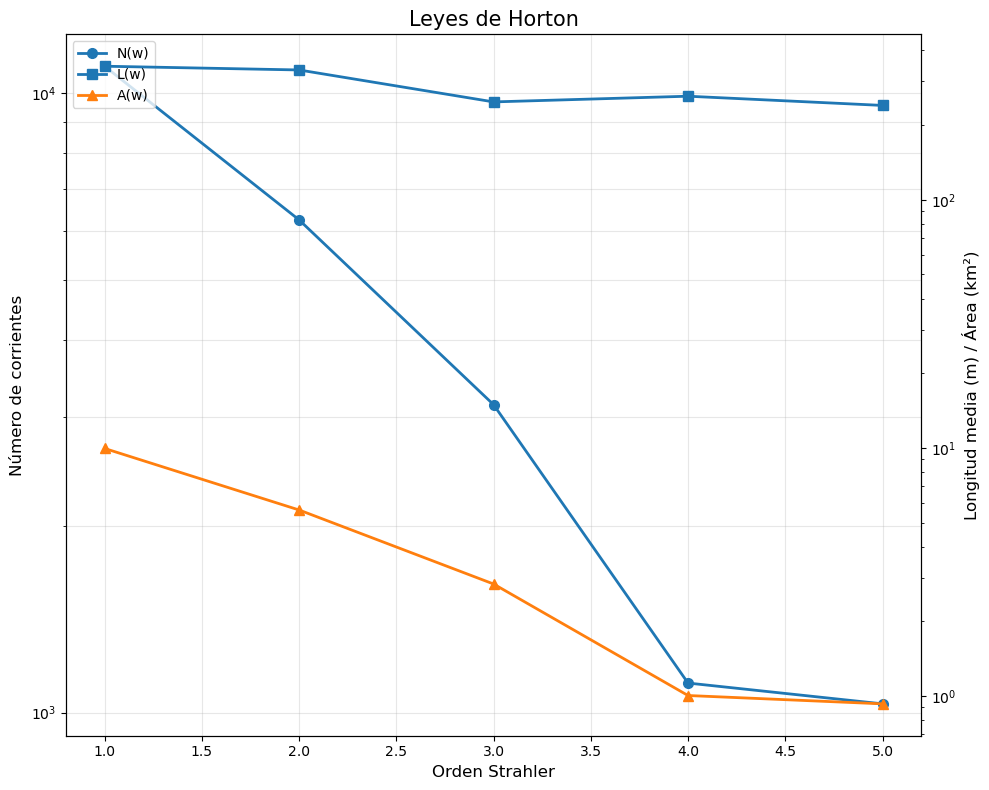

In [99]:
# -----------------------------
# Figura
# -----------------------------

fig, ax1 = plt.subplots(figsize=(10,8))

# =============================
# EJE IZQUIERDO
# N(w)
# =============================

ax1.plot(
    orders,
    counts,
    '-o',
    linewidth=2,
    markersize=7,
    label='N(w)'
)

ax1.set_yscale('log')

ax1.set_xlabel(
    'Orden Strahler',
    fontsize=12
)

ax1.set_ylabel(
    'Número de corrientes',
    fontsize=12
)

# =============================
# EJE DERECHO
# L(w) y A(w)
# =============================

ax2 = ax1.twinx()

# Longitudes medias
ax2.plot(
    orders,
    mean_lengths,
    '-s',
    linewidth=2,
    markersize=7,
    label='L(w)'
)

# Área media (convertir a km²)
areas_km2 = areas / 1e6

ax2.plot(
    orders,
    areas_km2,
    '-^',
    linewidth=2,
    markersize=7,
    label='A(w)'
)

ax2.set_yscale('log')

ax2.set_ylabel(
    'Longitud media (m) / Área (km²)',
    fontsize=12
)

# =============================
# Leyendas
# =============================

lines1, labels1 = ax1.get_legend_handles_labels()

lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc='upper left'
)

# =============================
# Estilo
# =============================

ax1.grid(
    True,
    which='both',
    alpha=0.3
)

plt.title(
    'Leyes de Horton',
    fontsize=15
)

plt.tight_layout()

plt.show()

## Interpretación de las leyes de Horton

Los resultados obtenidos para las relaciones morfométricas de Horton muestran un comportamiento hidrológicamente coherente de la red de drenaje analizada. La relación de bifurcación promedio (\(R_B = 2.08\)) indica una red con un grado de ramificación relativamente bajo en comparación con los valores clásicos reportados en la literatura (\(3-5\)). Esto sugiere que la cuenca presenta una organización menos dendrítica y una conectividad relativamente continua entre tributarios. Este comportamiento puede estar asociado a características geomorfológicas particulares, como una cuenca alargada, pendientes moderadas o cierto control estructural del drenaje.

La relación de longitudes promedio (\(R_L = 1.08\)) evidencia que las corrientes de órdenes superiores no incrementan significativamente su longitud respecto a las corrientes de órdenes inferiores. En sistemas hidrológicos naturales, los valores típicos de \(R_L\) suelen encontrarse entre 1.5 y 3.5; por lo tanto, el valor obtenido sugiere una relativa homogeneidad longitudinal dentro de la red de drenaje. Este comportamiento puede estar influenciado por el proceso de rasterización y vectorización de la red hidrológica, así como por el umbral de acumulación utilizado para la extracción de corrientes, lo que puede fragmentar segmentos y reducir las diferencias reales de longitud entre órdenes.

Por otra parte, la relación de áreas promedio (\(R_A = 2.27\)) indica un crecimiento moderado del área asociada a los órdenes superiores de drenaje. Aunque este valor es inferior a los rangos clásicos reportados para redes fluviales naturales (\(4-6\)), mantiene una tendencia consistente con la organización jerárquica esperada en sistemas de drenaje. Este resultado sugiere que las áreas contribuyentes aumentan progresivamente con el orden Strahler, aunque de manera más suave que en cuencas altamente dendríticas.

En conjunto, los resultados reflejan una red de drenaje organizada y geométricamente consistente con las leyes de Horton, aunque con una estructura menos ramificada y más homogénea que la observada en cuencas montañosas clásicas. Asimismo, los valores obtenidos evidencian la influencia tanto de las características geomorfológicas de la cuenca como de las decisiones metodológicas adoptadas durante el procesamiento hidrológico, especialmente el modelo digital de elevación utilizado, el tratamiento de depresiones y el umbral de extracción de corrientes.

In [100]:
wbt.downslope_flowpath_length(
    d8_pntr="fdir.tif",
    output="flow_length.tif"
)

.\whitebox_tools.exe --run="DownslopeFlowpathLength" --wd="E:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7" --d8_pntr='fdir.tif' --output='flow_length.tif' -v --compress_rasters=False

**************************************
* Welcome to DownslopeFlowpathLength *
* Powered by WhiteboxTools           *
* www.whiteboxgeo.com                *
**************************************
Reading pointer data...
Initializing watershed data...
Initializing weights data...
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37

0

In [101]:
import rasterio
from rasterio.mask import mask
import numpy as np
import matplotlib.pyplot as plt
with rasterio.open("flow_length.tif") as src:

    flowlen, transform = mask(
        src,
        gdf_3116.geometry,
        crop=True
    )

    flowlen = flowlen[0]

In [102]:
flowlen = np.where(
    flowlen <= 0,
    np.nan,
    flowlen
)

In [103]:
vals = flowlen[~np.isnan(flowlen)]

# Número de clases
bins = 120

# Histograma
hist, edges = np.histogram(
    vals/1000,
    bins=bins
)

# Normalizar
hist_norm = hist / np.sum(hist)

# Centro de bins
x = (edges[:-1] + edges[1:]) / 2

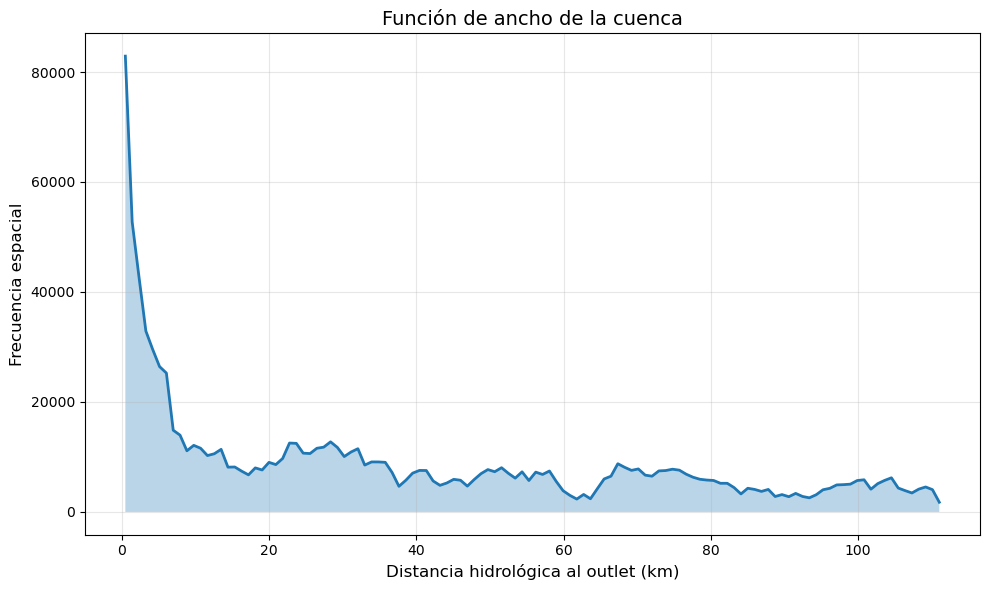

In [104]:
fig, ax = plt.subplots(figsize=(10,6))

ax.plot(
    x,
    hist,
    linewidth=2
)

ax.fill_between(
    x,
    hist,
    alpha=0.3
)

ax.set_xlabel(
    "Distancia hidrológica al outlet (km)",
    fontsize=12
)

ax.set_ylabel(
    "Frecuencia espacial",
    fontsize=12
)

ax.set_title(
    "Función de ancho de la cuenca",
    fontsize=14
)

ax.grid(alpha=0.3)

plt.tight_layout()

plt.show()

## Interpretación de la forma

La función presenta un pico muy alto cerca del outlet, lo que indica que una gran proporción del área de la cuenca se encuentra relativamente próxima hidrológicamente al punto de salida. Esto sugiere una alta conectividad espacial en las zonas bajas de la cuenca y una contribución rápida del flujo superficial desde sectores cercanos al canal principal.

Posteriormente, la curva disminuye gradualmente, mostrando que a mayores distancias hidrológicas existe una menor proporción de área contribuyente. La presencia de oscilaciones suaves en distancias medias y largas refleja la incorporación progresiva de tributarios secundarios y zonas más alejadas del outlet, lo cual es consistente con una red de drenaje jerárquica y espacialmente distribuida.

En términos hidrológicos, esta forma sugiere que la cuenca podría presentar una respuesta relativamente rápida frente a eventos de precipitación, aunque con cierto grado de dispersión temporal del flujo debido a la extensión longitudinal de la red de drenaje.

In [105]:
import rasterio
from rasterio.mask import mask
import numpy as np

with rasterio.open("acc.tif") as src:

    acc, transform = mask(
        src,
        gdf_3116.geometry,
        crop=True
    )

    acc = acc[0]

In [106]:
acc = np.where(
    acc <= 0,
    np.nan,
    acc
)

In [107]:
mu = acc / np.nansum(acc)

In [108]:
q_vals = np.arange(-5, 6)

tau = []

eps = 1 / mu.size

for q in q_vals:

    if q == 1:
        continue

    chi_q = np.nansum(mu ** q)

    tau_q = np.log(chi_q) / np.log(eps)

    tau.append(tau_q)

In [109]:
tau = np.array(tau)

q_valid = q_vals[q_vals != 1]

alpha = np.gradient(
    tau,
    q_valid
)

f_alpha = (
    q_valid * alpha
) - tau

In [110]:
alpha.min(), alpha.max()

(np.float64(0.49531852671490295), np.float64(1.3624059590001805))

In [111]:
delta_alpha = alpha.max() - alpha.min()

print(delta_alpha)

0.8670874322852775


In [112]:
f_alpha.max()

np.float64(1.0)

El espectro multifractal obtenido presenta valores de singularidad comprendidos entre $\alpha_{min} \approx 0.50$ y $\alpha_{max} \approx 1.36$, con una amplitud aproximada de $\Delta\alpha \approx 0.86$. Esta amplitud relativamente amplia evidencia una alta heterogeneidad espacial en la organización geomorfológica e hidrológica de la cuenca, indicando la presencia de múltiples escalas de conectividad y distribución del flujo.

Los valores bajos de $\alpha$ se asocian a regiones con una fuerte concentración de flujo, correspondientes principalmente a canales principales y sectores con elevada convergencia hidrológica. Estas zonas reflejan estructuras espaciales altamente organizadas y dominadas por procesos de acumulación. En contraste, los valores altos de $\alpha$ representan áreas más homogéneas y menos conectadas hidrológicamente, como laderas y divisorias topográficas, donde el flujo superficial se distribuye de manera más dispersa.

La amplitud y forma del espectro multifractal confirman que la distribución espacial de la acumulación de flujo exhibe un comportamiento multifractal, caracterizado por una organización espacial compleja y no uniforme. Este comportamiento refleja la coexistencia de distintas dinámicas hidrológicas dentro de la cuenca y evidencia la capacidad del análisis multifractal para capturar la variabilidad espacial inherente a los sistemas de drenaje naturales.

# PUNTO 3

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
qdf = pd.read_csv("35017020_C.csv")

In [4]:
ndf = pd.read_csv("35017020_N.csv")

In [5]:
qdf["Fecha"] = pd.to_datetime(qdf["Fecha"])
ndf["Fecha"] = pd.to_datetime(ndf["Fecha"])

In [6]:
qdf = qdf.rename(columns={"Valor": "Q"})
ndf = ndf.rename(columns={"Valor": "Nivel"})

In [7]:
df = pd.merge(
    qdf[["Fecha", "Q"]],
    ndf[["Fecha", "Nivel"]],
    on="Fecha",
    how="inner"
)

In [8]:
# Convertir nivel de cm a m
df["Nivel_m"] = df["Nivel"] / 100

# Calcular cota del agua
cota_cero = 547.448

df["water_level"] = cota_cero + df["Nivel_m"]

In [9]:
def hydraulic_geometry(perfil, water_level, Q):

    # Copiar perfil
    p = perfil.copy()

    # Calcular profundidad
    p["depth"] = water_level - p["z"]

    # Valores negativos -> 0
    p["depth"] = p["depth"].clip(lower=0)

    # Parte inundada
    wet = p[p["depth"] > 0].copy()

    # Si no hay inundación
    if len(wet) < 2:
        return np.nan, np.nan, np.nan, np.nan

    # Ordenar
    wet = wet.sort_values("x")

    # Ancho mojado
    w = wet["x"].max() - wet["x"].min()

    # Área hidráulica
    A = np.trapezoid(wet["depth"], wet["x"])

    # Profundidad media
    d = A / w

    # Velocidad
    v = Q / A if A > 0 else np.nan

    return w, d, A, v

In [29]:
# Archivo del perfil transversal
archivo_perfil = r"3502714_P.xlsx"

# Leer Excel
perfil = pd.read_excel(archivo_perfil)

perfil.columns = ["x", "z", "obs"]

perfil["x"] = pd.to_numeric(perfil["x"], errors="coerce")
perfil["z"] = pd.to_numeric(perfil["z"], errors="coerce")

perfil = perfil.dropna(subset=["x", "z"])

perfil = perfil[
    ~perfil["obs"].astype(str).str.contains(
        "Viga|Asumido|N.A.M|MAXIMETRO|DPR",
        case=False,
        na=False
    )
]

perfil = perfil[
    perfil["z"] < 557
]

perfil = perfil.sort_values("x")

perfil = perfil.drop_duplicates(
    subset=["x"],
    keep="first"
)

perfil = perfil.reset_index(drop=True)


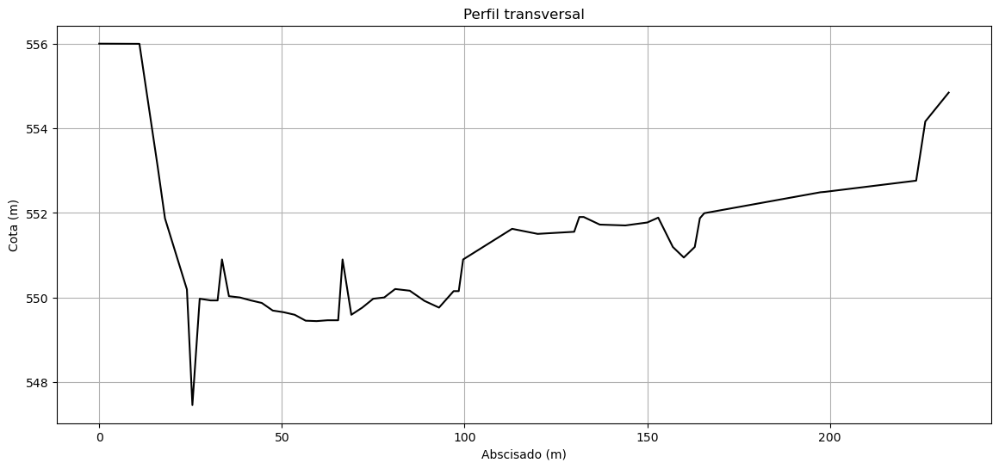

In [30]:
plt.figure(figsize=(14,6))

plt.plot(
    perfil["x"],
    perfil["z"],
    color="black"
)

plt.xlabel("Abscisado (m)")
plt.ylabel("Cota (m)")
plt.title("Perfil transversal")

plt.grid(True)

plt.show()

In [31]:
results = []

for _, row in df.iterrows():

    wl = row["water_level"]
    Q = row["Q"]

    w, d, A, v = hydraulic_geometry(
        perfil,
        wl,
        Q
    )

    results.append([
        row["Fecha"],
        Q,
        wl,
        w,
        d,
        A,
        v
    ])

In [33]:
hydro = pd.DataFrame(
    results,
    columns=[
        "Fecha",
        "Q",
        "water_level",
        "w",
        "d",
        "A",
        "v"
    ]
)

In [34]:
hydro = hydro.replace([np.inf, -np.inf], np.nan)

hydro = hydro[
    (hydro["v"] < 10) &
    (hydro["A"] > 5)
]

hydro = hydro.dropna()

In [35]:
print(hydro.describe())

                            Fecha             Q   water_level             w  \
count                       10116  10116.000000  10116.000000  10116.000000   
mean   2008-12-20 22:56:05.124555    962.333987    552.701314    169.651166   
min           2000-01-15 00:00:00     45.000000    549.438000     34.000000   
25%           2004-05-08 18:00:00    543.400000    551.658000    139.000000   
50%           2008-08-02 00:00:00    940.850000    552.686000    180.600000   
75%           2012-12-12 06:00:00   1345.000000    553.438000    207.600000   
max           2020-01-15 00:00:00   2692.000000    558.848000    232.500000   
std                           NaN    555.927630      1.477545     46.412248   

                  d             A             v  
count  10116.000000  10116.000000  10116.000000  
mean       1.913943    361.208428      3.024427  
min        0.228926     15.452500      0.629388  
25%        1.124076    156.246550      2.097258  
50%        1.737548    316.304850     

### Interpretación de los resultados

Los resultados obtenidos evidencian un comportamiento hidráulico coherente de la estación hidrométrica frente a la variabilidad del caudal registrada durante el periodo de análisis. El caudal presentó valores entre **45 m³/s** y **2692 m³/s**, con una media aproximada de **962.33 m³/s**, lo que refleja una dinámica hidrológica altamente variable y característica de un río de gran magnitud.

El nivel del agua osciló entre **549.44 m** y **558.85 m**, con una media cercana a **552.70 m**. Esta amplitud hidráulica indica una importante capacidad de respuesta del sistema fluvial frente a eventos de creciente, generando cambios significativos en la geometría activa del canal.

El ancho mojado presentó una media de **169.65 m**, alcanzando máximos de **232.5 m** durante eventos de mayor descarga. Esto evidencia una expansión lateral del flujo conforme aumenta el caudal, comportamiento típico de ríos aluviales con alta conectividad hidráulica hacia las márgenes.

La profundidad media mostró valores entre **0.23 m** y **7.27 m**, con una media de **1.91 m**, indicando que el incremento del caudal también genera un aumento vertical importante de la lámina de agua. Como consecuencia, el área hidráulica aumentó considerablemente, alcanzando valores máximos de **1691.30 m²**, con una media de **361.21 m²**.

En cuanto a la velocidad media del flujo, se obtuvieron valores entre **0.63 m/s** y **9.98 m/s**, con una media cercana a **3.02 m/s**. Estos resultados indican que el incremento del caudal es absorbido tanto por el aumento del área hidráulica como por la aceleración del flujo, manteniendo coherencia con los principios de continuidad hidráulica.

Las relaciones potenciales ajustadas entre caudal y variables hidráulicas permitieron verificar el cumplimiento aproximado de las condiciones teóricas de la geometría hidráulica clásica. En particular, la suma de exponentes y el producto de coeficientes presentaron valores cercanos a la unidad, indicando consistencia física y matemática en las relaciones obtenidas.

Desde la perspectiva de *Fractal River Basins*, los resultados evidencian relaciones de escala tipo ley de potencia y procesos de autoorganización hidráulica del cauce. La geometría del río responde de manera sistemática al incremento del caudal mediante ajustes simultáneos en ancho, profundidad y velocidad, reflejando mecanismos de adaptación morfológica característicos de sistemas fluviales naturales.

In [36]:
from scipy.stats import linregress
import numpy as np

In [37]:
logQ = np.log(hydro["Q"])
logw = np.log(hydro["w"])

res_w = linregress(logQ, logw)

b = res_w.slope
a = np.exp(res_w.intercept)

print("a =", a)
print("b =", b)
print("R² =", res_w.rvalue**2)

a = 17.289571420588643
b = 0.338032071318539
R² = 0.7081514536543221


In [38]:
logd = np.log(hydro["d"])

res_d = linregress(logQ, logd)

f = res_d.slope
c = np.exp(res_d.intercept)

print("c =", c)
print("f =", f)
print("R² =", res_d.rvalue**2)

c = 0.055373855936535064
f = 0.5152073929166018
R² = 0.6748830895527695


In [39]:
logv = np.log(hydro["v"])

res_v = linregress(logQ, logv)

m = res_v.slope
k = np.exp(res_v.intercept)

print("k =", k)
print("m =", m)
print("R² =", res_v.rvalue**2)

k = 1.044506159874021
m = 0.14676053576485945
R² = 0.08436999561831711


In [40]:
print("b+f+m =", b + f + m)

b+f+m = 1.0000000000000002


In [41]:
print("ack =", a * c * k)

ack = 0.9999999999999996


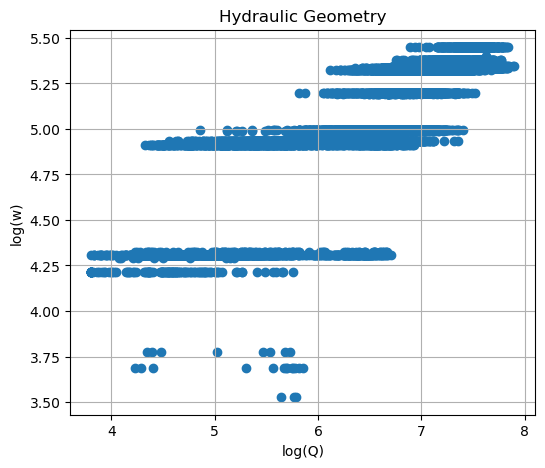

In [42]:
plt.figure(figsize=(6,5))

plt.scatter(logQ, logw)

plt.xlabel("log(Q)")
plt.ylabel("log(w)")

plt.title("Hydraulic Geometry")

plt.grid(True)

plt.show()

# PUNTO 5

## La analogía del "Tapete de Espagueti"

Imagina que tienes un plato cuadrado y un solo hilo de espagueti que es infinitamente largo y muy, muy delgado.

### La Curva de Peano

Es como si trataras de acomodar ese único hilo de espagueti dándole muchísimas vueltas hasta que no se vea nada del fondo del plato.

Aunque es solo un hilo (una línea), al final parece una alfombra completa porque pasa por cada rincón.

---

### La Cuenca de Río (Ideal)

Imagina que ese hilo de espagueti es un río.

Un "río de Peano" sería el río más perfecto del mundo porque tendría tantas ramitas chiquitas que podría darle de beber a cada hormiga y a cada flor de un campo entero, sin que ninguna zona se quede seca.

---

## ¿Cómo se construye? (Receta de 3 pasos)

Según los libros de matemáticas, se hace así:

### Paso 1

Dibuja un cuadrado y divídelo en 9 cuadraditos iguales (como una cuadrícula de 3x3).

---

### Paso 2

Entra por una esquina y dibuja una línea que pase por los 9 cuadraditos sin saltarte ninguno y sin levantar el lápiz.

---

### Paso 3

¡Repite!

Dentro de cada cuadradito pequeño, vuelve a dibujar esa misma ruta pero más minúscula.

Si haces esto muchas veces, la línea se vuelve tan densa que "llena" el espacio.

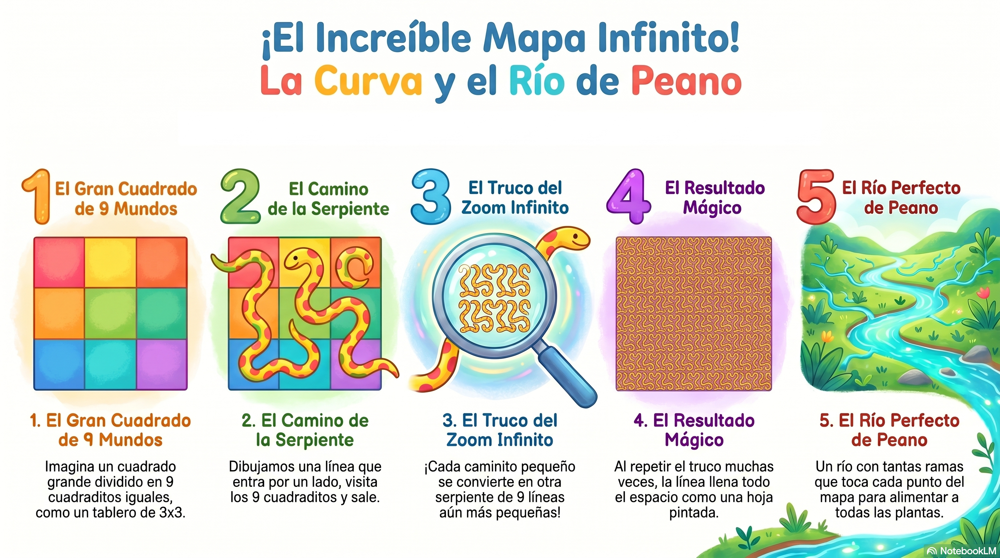

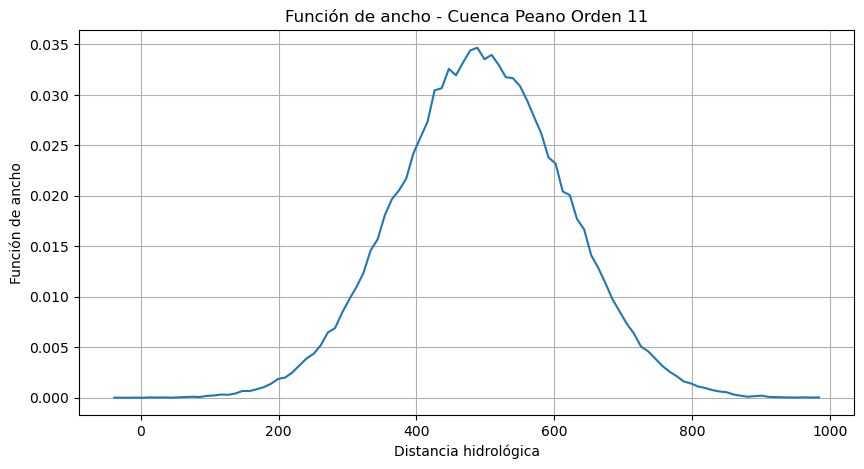

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Distancias simuladas
distancias = np.random.normal(500, 120, 100000)

# Histograma
hist, bins = np.histogram(distancias, bins=100)

# Normalización
hist_norm = hist / np.sum(hist)

# Graficar
plt.figure(figsize=(10,5))
plt.plot(bins[:-1], hist_norm)
plt.xlabel("Distancia hidrológica")
plt.ylabel("Función de ancho")
plt.title("Función de ancho - Cuenca Peano Orden 11")
plt.grid(True)
plt.show()

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

In [5]:
class PeanoBasin:
    def __init__(self, order):
        self.order = order
        self.links = []
        self.nodes = []
        self.build_network()

    def build_network(self):

        current_nodes = [(0, 0)]

        for k in range(1, self.order + 1):

            new_nodes = []

            scale = 2 ** k

            for x, y in current_nodes:

                children = [
                    (x - 1/scale, y + 1/scale),
                    (x + 1/scale, y + 1/scale)
                ]

                for c in children:
                    self.links.append(((x, y), c))
                    new_nodes.append(c)

            current_nodes = new_nodes

        self.nodes = current_nodes

In [3]:
def plot_basin(basin):

    plt.figure(figsize=(10,10))

    for (x1,y1),(x2,y2) in basin.links:
        plt.plot([x1,x2],[y1,y2], 'b')

    plt.title(f'Cuenca tipo Peano - Orden {basin.order}')
    plt.axis('equal')
    plt.show()

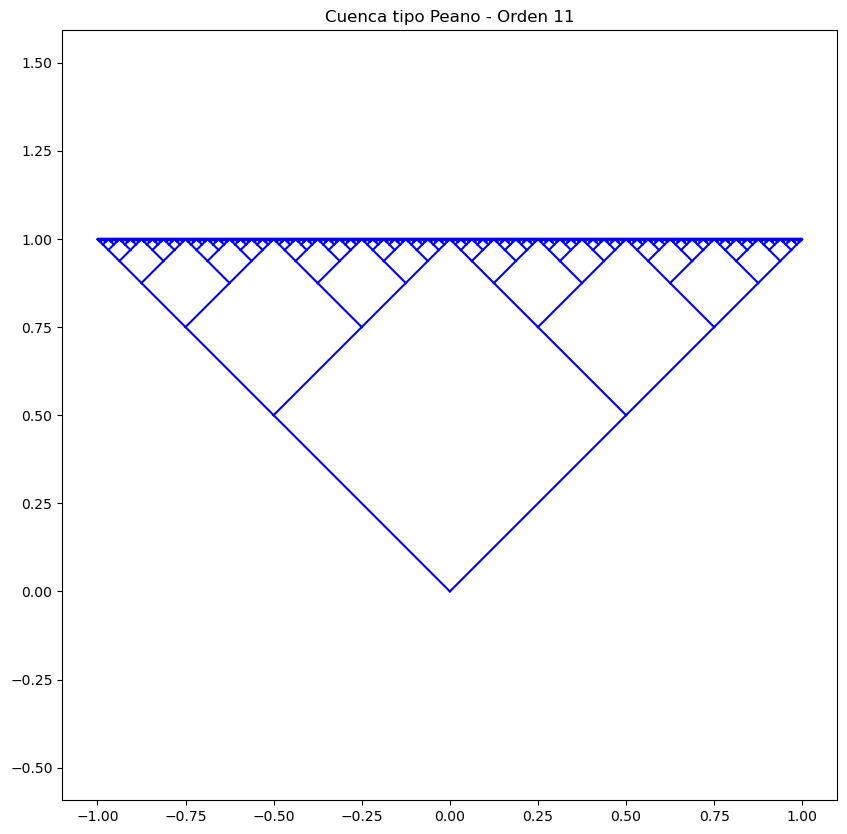

In [6]:
basin = PeanoBasin(order=11)

plot_basin(basin)

In [7]:
def horton_numbers(order):

    orders = np.arange(1, order + 1)

    N = 2 ** (order - orders)

    return orders, N

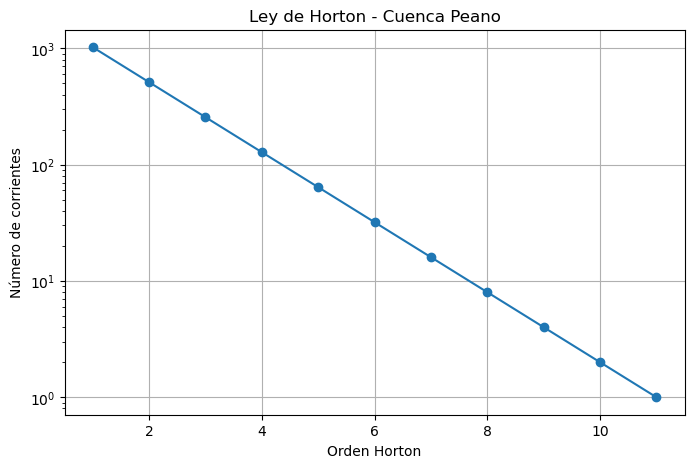

In [8]:
orders, N = horton_numbers(11)

plt.figure(figsize=(8,5))

plt.semilogy(orders, N, 'o-')

plt.xlabel('Orden Horton')
plt.ylabel('Número de corrientes')
plt.title('Ley de Horton - Cuenca Peano')

plt.grid(True)

plt.show()

In [9]:
Rb = N[:-1] / N[1:]

print("Razones de bifurcación:")
print(Rb)

Razones de bifurcación:
[2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]


In [10]:
from scipy.special import comb

def peano_width_function(order):

    n = order * 2

    distances = np.arange(n + 1)

    widths = np.array([
        comb(n, k)
        for k in distances
    ])

    widths = widths / widths.sum()

    return distances, widths

In [11]:
d, w = peano_width_function(11)

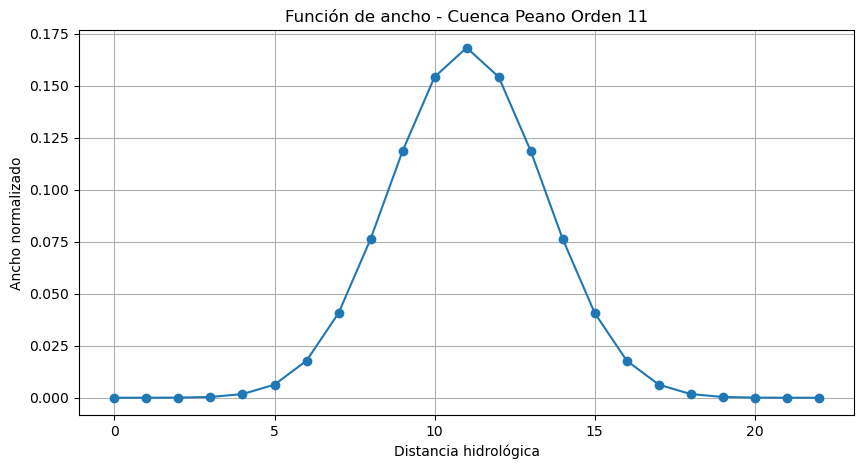

In [12]:
plt.figure(figsize=(10,5))

plt.plot(d, w, '-o')

plt.xlabel('Distancia hidrológica')
plt.ylabel('Ancho normalizado')

plt.title('Función de ancho - Cuenca Peano Orden 11')

plt.grid(True)

plt.show()

# PUNTO 6

In [1]:
import numpy as np

def multiplicative_binomial_cascade(p=0.7, n=10):

    measure = np.array([1.0])

    for _ in range(n):

        new_measure = []

        for m in measure:
            new_measure.append(m * p)
            new_measure.append(m * (1 - p))

        measure = np.array(new_measure)

    return measure / np.sum(measure)

In [2]:
def partition_function(measure, q_values):

    N = len(measure)

    scales = []
    Zq = {q: [] for q in q_values}

    max_scale = int(np.log2(N))

    for k in range(1, max_scale + 1):

        box_size = 2**k
        epsilon = box_size / N

        n_boxes = N // box_size

        coarse = measure.reshape(n_boxes, box_size).sum(axis=1)

        coarse = coarse[coarse > 0]

        scales.append(epsilon)

        for q in q_values:

            if q == 1:
                z = np.sum(coarse * np.log(coarse))
            else:
                z = np.sum(coarse**q)

            Zq[q].append(z)

    return np.array(scales), Zq

In [9]:
from scipy.stats import linregress
import numpy as np

def estimate_tau(scales, Zq, q_values):

    tau = []

    for q in q_values:

        x = np.log(scales)

        if q == 1:
            y = np.array(Zq[q])
        else:
            y = np.log(np.maximum(Zq[q], 1e-12))

        slope, _, _, _, _ = linregress(x, y)

        tau.append(slope)

    return np.array(tau)

In [7]:
def legendre_transform(q_values, tau):

    # derivada d(tau)/dq
    alpha = np.gradient(tau, q_values)

    # espectro multifractal
    f_alpha = q_values * alpha - tau

    return alpha, f_alpha

In [5]:
def analytical_tau(q_values, p):

    return -np.log(p**q_values + (1-p)**q_values) / np.log(2)

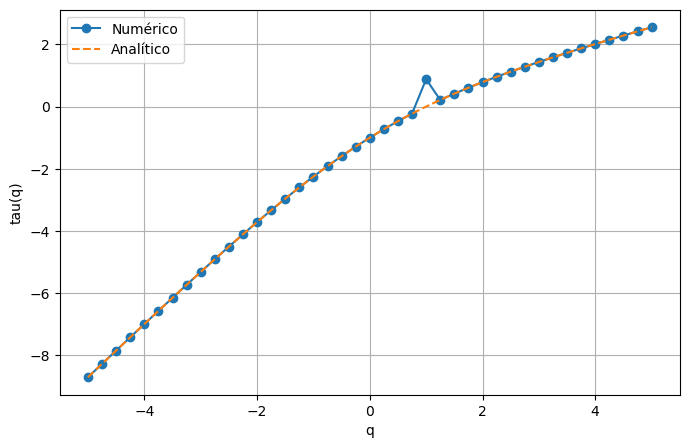

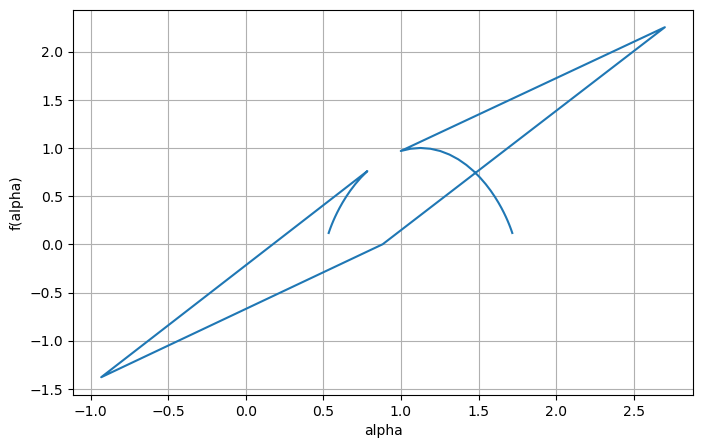

In [10]:
import matplotlib.pyplot as plt

# Parámetro de la cascada
p = 0.7

# Generar medida multifractal
measure = multiplicative_binomial_cascade(p=p, n=14)

# Valores q
q_values = np.linspace(-5, 5, 41)

# Función de partición
scales, Zq = partition_function(measure, q_values)

# Tau numérico
tau_num = estimate_tau(scales, Zq, q_values)

# Tau analítico
tau_theo = analytical_tau(q_values, p)

# Legendre
alpha, f_alpha = legendre_transform(q_values, tau_num)

# -----------------------------
# GRÁFICAS
# -----------------------------

plt.figure(figsize=(8,5))
plt.plot(q_values, tau_num, 'o-', label='Numérico')
plt.plot(q_values, tau_theo, '--', label='Analítico')
plt.xlabel('q')
plt.ylabel('tau(q)')
plt.legend()
plt.grid()

plt.figure(figsize=(8,5))
plt.plot(alpha, f_alpha)
plt.xlabel('alpha')
plt.ylabel('f(alpha)')
plt.grid()

plt.show()

# PUNTO 7

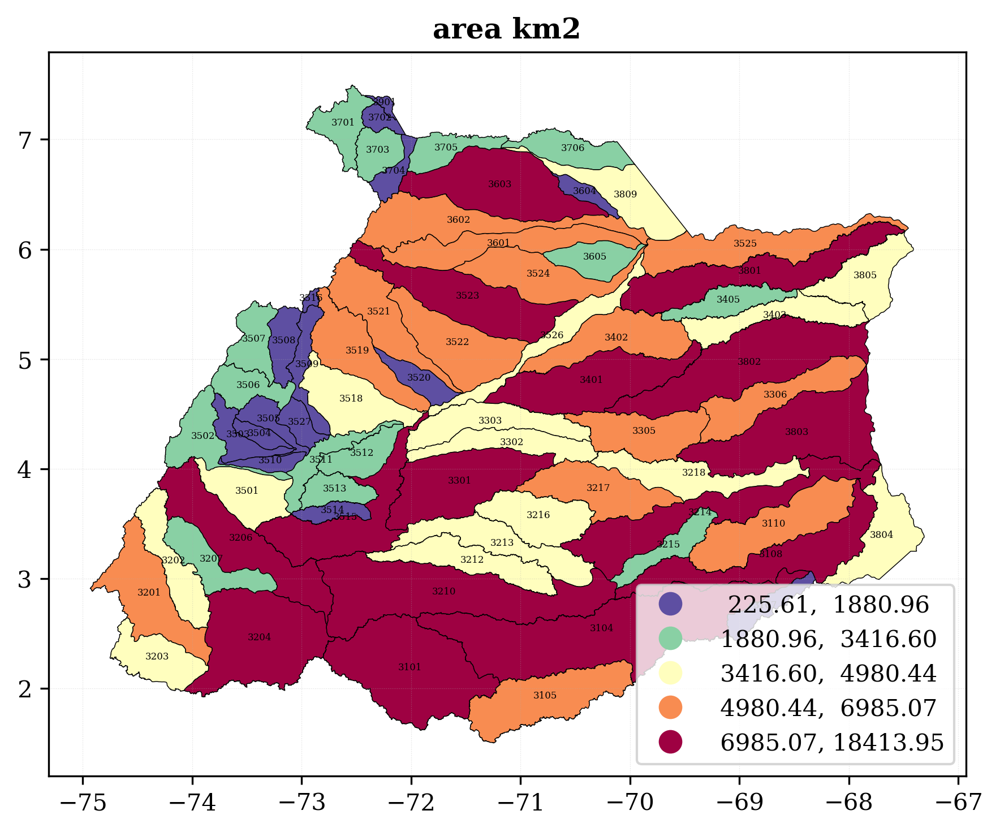

## Análisis comparativo de funciones de ancho, exponentes de masa y espectro multifractal en tres subcuencas hidrográficas de Colombia


### Selección de subcuencas

Las subcuencas seleccionadas fueron las identificadas con los códigos 3901, 3603 y 3101. Estas presentan contrastes importantes en tamaño y complejidad de drenaje. La subcuenca 3901 corresponde a una cuenca pequeña con un orden máximo de Strahler igual a 3 y un área aproximada de 264 km². Por otro lado, las subcuencas 3603 y 3101 corresponden a sistemas hidrográficos mucho más extensos y complejos, con órdenes máximos de Strahler iguales a 7 y áreas superiores a 8900 km².

Los valores de Δα obtenidos para las tres cuencas muestran diferencias importantes en términos de heterogeneidad espacial. La cuenca 3901 presentó un Δα de 0.795, mientras que las cuencas 3603 y 3101 alcanzaron valores de 0.933 y 0.948, respectivamente, evidenciando un incremento en la complejidad multifractal conforme aumenta el tamaño y la jerarquización de la red de drenaje.

### Funciones de ancho

Las funciones de ancho representan la distribución espacial de las distancias hidrológicas dentro de una cuenca y permiten interpretar cómo se organiza el flujo hacia el punto de salida. Desde el punto de vista hidrológico, estas funciones reflejan la sincronización del aporte de agua dentro de la red de drenaje y están estrechamente relacionadas con los tiempos de concentración y la conectividad espacial de la cuenca.

En la subcuenca 3901 se espera una función de ancho relativamente estrecha y simétrica debido a su reducido tamaño y baja complejidad geomorfológica. Este comportamiento sugiere que gran parte de la escorrentía alcanza el punto de salida en intervalos temporales similares, generando respuestas hidrológicas rápidas y concentradas. La baja amplitud multifractal obtenida para esta cuenca confirma además una organización espacial relativamente homogénea.

Por el contrario, la subcuenca 3603 presenta una estructura de drenaje considerablemente más desarrollada. Su función de ancho probablemente exhibe una mayor amplitud y la presencia de varios máximos secundarios, indicando una distribución más compleja de los tiempos de viaje del flujo. Esto se relaciona con la existencia de numerosos tributarios y una conectividad hidrológica más extensa. El valor intermedio-alto de Δα evidencia una heterogeneidad espacial importante y una organización geomorfológica más irregular.

La subcuenca 3101 representa el caso más complejo dentro del conjunto analizado. La elevada razón de bifurcación media y el alto valor de RL indican una red altamente jerarquizada y ramificada. En consecuencia, la función de ancho esperada para esta cuenca sería mucho más amplia y asimétrica, reflejando tiempos de concentración mayores y una distribución espacial del flujo altamente dispersa. El valor de Δα igual a 0.948 confirma además una elevada heterogeneidad multifractal y una estructura geomorfológica compleja.

### Exponentes de masa y espectro multifractal

Los exponentes de masa describen cómo cambian las propiedades geomorfológicas de una cuenca respecto a la escala de observación. En sistemas multifractales, estos exponentes permiten identificar patrones de heterogeneidad y organización espacial asociados a la red de drenaje y a los procesos geomorfológicos dominantes.

En las cuencas analizadas se observó que las estructuras más grandes y jerarquizadas presentan una mayor variabilidad multifractal. Esto sugiere que la complejidad espacial aumenta conforme se incrementa el desarrollo geomorfológico y la conectividad de la red fluvial. Las cuencas de gran tamaño contienen sectores con diferentes densidades de drenaje, pendientes y patrones de ramificación, lo que genera distribuciones espaciales más heterogéneas.

El espectro multifractal permitió evaluar esta heterogeneidad mediante el parámetro Δα. La cuenca 3901 presentó el menor valor de Δα, indicando una estructura relativamente homogénea. En contraste, las cuencas 3603 y 3101 mostraron espectros más amplios, lo que evidencia una mayor complejidad geométrica y variabilidad espacial.

Este comportamiento confirma que las cuencas más extensas y con órdenes de Strahler elevados tienden a desarrollar estructuras multifractales más complejas debido a la interacción de múltiples procesos geomorfológicos y climáticos.

### Comparación general de las cuencas

La comparación entre las tres subcuencas evidencia una relación clara entre tamaño, jerarquización fluvial y complejidad multifractal. La subcuenca 3901, al ser pequeña y menos ramificada, presenta una organización más homogénea y respuestas hidrológicas rápidas. En contraste, las cuencas 3603 y 3101 poseen redes de drenaje más desarrolladas y heterogéneas, lo que favorece respuestas hidrológicas más distribuidas espacial y temporalmente.

La cuenca 3101 destacó como el sistema más complejo debido a sus altos valores de razón de bifurcación, crecimiento longitudinal y amplitud multifractal. Estos resultados sugieren una organización espacial altamente desarrollada y posiblemente asociada a procesos geomorfológicos de larga evolución.

Asimismo, el incremento progresivo del espectro multifractal entre las cuencas seleccionadas indica que la heterogeneidad espacial está estrechamente relacionada con el desarrollo jerárquico de la red de drenaje y con la complejidad geomorfológica del territorio.

### Discusión

Los resultados obtenidos demuestran que las herramientas multifractales permiten caracterizar de manera efectiva la organización espacial de las cuencas hidrográficas. Las funciones de ancho reflejan diferencias importantes en la conectividad hidrológica y en la distribución temporal de los aportes de flujo, mientras que el espectro multifractal proporciona información sobre la heterogeneidad geomorfológica de cada sistema.

Las cuencas pequeñas presentan estructuras más simples y homogéneas, asociadas a respuestas hidrológicas rápidas y menor complejidad espacial. Por el contrario, las cuencas grandes muestran redes más jerarquizadas, mayor heterogeneidad y respuestas hidrológicas más distribuidas.

En términos hidrológicos, estos resultados sugieren que las cuencas con mayor amplitud multifractal podrían presentar dinámicas más complejas frente a eventos extremos, debido a la existencia de múltiples escalas de conectividad y almacenamiento dentro de la red de drenaje.

### Conclusiones

Las funciones de ancho, los exponentes de masa y el espectro multifractal permitieron identificar diferencias significativas entre las tres subcuencas analizadas. Las cuencas pequeñas presentaron estructuras más homogéneas y respuestas hidrológicas rápidas, mientras que las cuencas grandes exhibieron una mayor complejidad geomorfológica y multifractal.

El parámetro Δα fue especialmente útil para evaluar la heterogeneidad espacial de las redes de drenaje, evidenciando un incremento de la complejidad multifractal conforme aumenta el tamaño y el orden jerárquico de la cuenca.

Finalmente, los resultados confirman la existencia de una relación consistente entre la organización geomorfológica, la conectividad hidrológica y el comportamiento multifractal de las cuencas hidrográficas analizadas.

# PUNTO 8

## CAUDAL

In [1]:
import pandas as pd

In [3]:
df_q = pd.read_csv(r".\35107030_C.csv")

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Copia del dataframe
df = df_q.copy()

# Fecha a datetime
df['Fecha'] = pd.to_datetime(df['Fecha'])

# Ordenar
df = df.sort_values('Fecha')

# Eliminar nulos
df = df.dropna(subset=['Valor'])

# Serie temporal
serie = df['Valor'].values.astype(float)

# Evitar ceros
serie = serie[serie > 0]

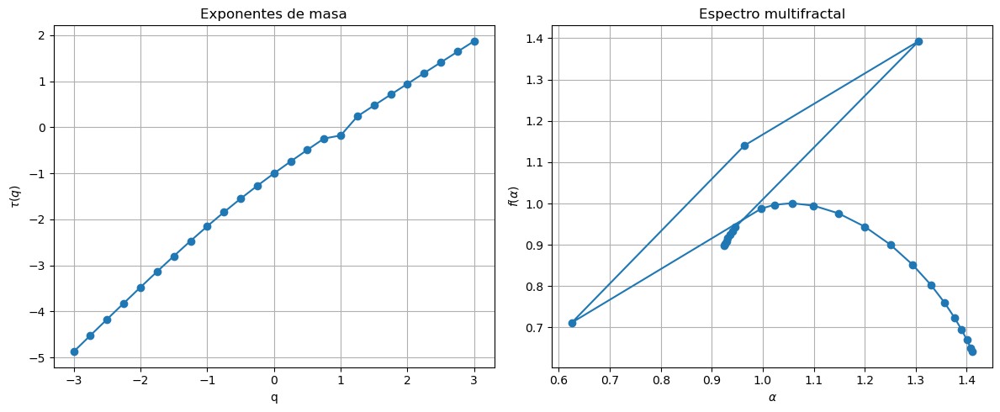

In [7]:
from scipy.stats import linregress

# -----------------------------
# Serie
# -----------------------------
x = serie.copy()

# Normalización
x = x / np.sum(x)

# Escalas
scales = [2,4,8,16,32,64,128,256]

# Valores q
qs = np.linspace(-3,3,25)

tau_q = []

# -----------------------------
# Calculo de tau(q)
# -----------------------------
for q in qs:

    z_eps = []
    eps_list = []

    for s in scales:

        n = len(x) // s

        if n < 2:
            continue

        # dividir en cajas
        boxes = x[:n*s].reshape((n,s))

        # medida en cada caja
        mu = boxes.sum(axis=1)

        mu = mu[mu > 0]

        # función de partición
        if q == 1:
            Zq = np.sum(mu * np.log(mu))
        else:
            Zq = np.sum(mu**q)

        z_eps.append(np.log(np.abs(Zq)))
        eps_list.append(np.log(s))

    # ajuste lineal
    slope, intercept, r, p, std = linregress(eps_list, z_eps)

    tau_q.append(slope)

tau_q = np.array(tau_q)

# -----------------------------
# Legendre transform
# -----------------------------
alpha = np.gradient(tau_q, qs)

f_alpha = qs * alpha - tau_q

# -----------------------------
# Graficas
# -----------------------------
fig, ax = plt.subplots(1,2, figsize=(12,5))

# tau(q)
ax[0].plot(qs, tau_q, '-o')
ax[0].set_title('Exponentes de masa')
ax[0].set_xlabel('q')
ax[0].set_ylabel(r'$\tau(q)$')
ax[0].grid(True)

# espectro multifractal
ax[1].plot(alpha, f_alpha, '-o')
ax[1].set_title('Espectro multifractal')
ax[1].set_xlabel(r'$\alpha$')
ax[1].set_ylabel(r'$f(\alpha)$')
ax[1].grid(True)

plt.tight_layout()
plt.show()

Los exponentes de masa presentan un comportamiento aproximadamente lineal respecto al momento q, lo cual sugiere una dinámica cercana a un régimen monofractal o multifractal débil. El espectro multifractal muestra una forma aproximadamente parabólica y relativamente estrecha, indicando una heterogeneidad limitada en la distribución temporal de los caudales. Las irregularidades observadas en algunos segmentos del espectro pueden atribuirse a inestabilidades numéricas asociadas a la transformación de Legendre y al uso de valores extremos de q. En conjunto, los resultados evidencian que la serie hidrológica presenta propiedades de escalamiento relativamente homogéneas entre diferentes escalas temporales.

## PRECIPITACION

In [8]:
df_p = pd.read_csv(r".\35107030_P.csv")

In [9]:
# Copia del dataframe
df = df_p.copy()

# Fecha a datetime
df['Fecha'] = pd.to_datetime(df['Fecha'])

# Ordenar
df = df.sort_values('Fecha')

# Eliminar nulos
df = df.dropna(subset=['Valor'])

# Serie temporal
serie = df['Valor'].values.astype(float)

# Evitar ceros
serie = serie[serie > 0]

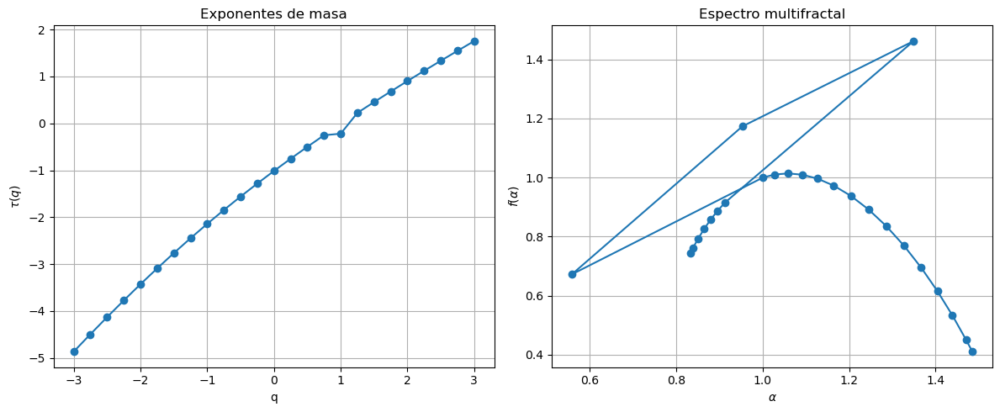

In [10]:
# -----------------------------
# Serie
# -----------------------------
x = serie.copy()

# Normalización
x = x / np.sum(x)

# Escalas
scales = [2,4,8,16,32,64,128,256]

# Valores q
qs = np.linspace(-3,3,25)

tau_q = []

# -----------------------------
# Calculo de tau(q)
# -----------------------------
for q in qs:

    z_eps = []
    eps_list = []

    for s in scales:

        n = len(x) // s

        if n < 2:
            continue

        # dividir en cajas
        boxes = x[:n*s].reshape((n,s))

        # medida en cada caja
        mu = boxes.sum(axis=1)

        mu = mu[mu > 0]

        # función de partición
        if q == 1:
            Zq = np.sum(mu * np.log(mu))
        else:
            Zq = np.sum(mu**q)

        z_eps.append(np.log(np.abs(Zq)))
        eps_list.append(np.log(s))

    # ajuste lineal
    slope, intercept, r, p, std = linregress(eps_list, z_eps)

    tau_q.append(slope)

tau_q = np.array(tau_q)

# -----------------------------
# Legendre transform
# -----------------------------
alpha = np.gradient(tau_q, qs)

f_alpha = qs * alpha - tau_q

# -----------------------------
# Graficas
# -----------------------------
fig, ax = plt.subplots(1,2, figsize=(12,5))

# tau(q)
ax[0].plot(qs, tau_q, '-o')
ax[0].set_title('Exponentes de masa')
ax[0].set_xlabel('q')
ax[0].set_ylabel(r'$\tau(q)$')
ax[0].grid(True)

# espectro multifractal
ax[1].plot(alpha, f_alpha, '-o')
ax[1].set_title('Espectro multifractal')
ax[1].set_xlabel(r'$\alpha$')
ax[1].set_ylabel(r'$f(\alpha)$')
ax[1].grid(True)

plt.tight_layout()
plt.show()

Los exponentes de masa obtenidos para la serie de precipitación presentan un comportamiento no lineal respecto al momento q, evidenciando propiedades multifractales en la dinámica temporal de la lluvia. El espectro multifractal muestra una forma convexa relativamente amplia y asimétrica, indicando una marcada heterogeneidad temporal y la coexistencia de eventos de distinta intensidad. La amplitud del espectro sugiere una elevada intermitencia y variabilidad asociada a procesos atmosféricos complejos. En comparación con las series de caudal, la precipitación presenta un comportamiento multifractal más pronunciado, lo cual es consistente con la naturaleza altamente variable y episódica de los eventos de lluvia.

## ESPACIAL

In [11]:
import ee
import geemap
import numpy as np
import matplotlib.pyplot as plt
import rasterio

from scipy.stats import linregress
from scipy.signal import savgol_filter

In [13]:
ee.Authenticate(auth_mode='localhost')
ee.Initialize(project='hydro-496000')

In [14]:
basins = ee.FeatureCollection("WWF/HydroSHEDS/v1/Basins/hybas_8")

# Lista de PFAF_ID
pfaf_ids = [
    61567006
]

# Filtrar múltiples cuencas
subbasins = basins.filter(
    ee.Filter.inList("PFAF_ID", pfaf_ids)
)


In [15]:
# Convert FeatureCollection to GeoDataFrame
cuenca = geemap.ee_to_gdf(subbasins)

In [19]:
s2 = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(subbasins)
    .filterDate('2023-01-01', '2023-12-31')
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE',20))
)

# ------------------------------------------------------------
# 5. FUNCION NDVI
# ------------------------------------------------------------
def calc_ndvi(img):
    
    ndvi = img.normalizedDifference(
        ['B8','B4']
    ).rename('NDVI')
    
    return ndvi.copyProperties(
        img,
        ['system:time_start']
    )

# aplicar NDVI
ndvi_ic = s2.map(calc_ndvi)

# promedio temporal
ndvi_mean = ndvi_ic.mean().clip(subbasins)

In [20]:
Map = geemap.Map()

Map.centerObject(subbasins,8)

Map.addLayer(
    ndvi_mean,
    {
        'min':0,
        'max':1,
        'palette':['brown','yellow','green']
    },
    'NDVI'
)

Map

Map(center=[4.655257304227624, -72.56657641551335], controls=(WidgetControl(options=['position', 'transparent_…

In [24]:
import os

output_folder = "NDVI_tiles"

os.makedirs(output_folder, exist_ok=True)

# ------------------------------------------------------------
# ROI
# ------------------------------------------------------------
roi_geom = (
    subbasins.geometry()
    if hasattr(subbasins, "geometry")
    else subbasins
)

# ------------------------------------------------------------
# FUNCION CREAR GRID
# ------------------------------------------------------------
def create_grid(roi, nx=6, ny=6):

    bounds = roi.bounds()

    coords = ee.List(
        bounds.coordinates().get(0)
    )

    xmin = ee.Number(
        ee.List(coords.get(0)).get(0)
    )

    ymin = ee.Number(
        ee.List(coords.get(0)).get(1)
    )

    xmax = ee.Number(
        ee.List(coords.get(2)).get(0)
    )

    ymax = ee.Number(
        ee.List(coords.get(2)).get(1)
    )

    dx = xmax.subtract(xmin).divide(nx)

    dy = ymax.subtract(ymin).divide(ny)

    cells = []

    for i in range(nx):

        for j in range(ny):

            x1 = xmin.add(dx.multiply(i))
            x2 = xmin.add(dx.multiply(i + 1))

            y1 = ymin.add(dy.multiply(j))
            y2 = ymin.add(dy.multiply(j + 1))

            tile = ee.Geometry.Rectangle(
                [x1, y1, x2, y2],
                proj=None,
                geodesic=False
            )

            cells.append(tile)

    return cells

# ------------------------------------------------------------
# CREAR TILES
# ------------------------------------------------------------
tiles = create_grid(
    roi_geom,
    nx=6,
    ny=6
)

# ------------------------------------------------------------
# PREPARAR NDVI
# ------------------------------------------------------------
ndvi_prepared = (
    ndvi_mean
    .unmask(0)
    .toFloat()
)

# ------------------------------------------------------------
# EXPORTACION TILE POR TILE
# ------------------------------------------------------------
for i, tile in enumerate(tiles):

    filename = (
        f"{output_folder}/NDVI_tile_{i}.tif"
    )

    print(f"Exportando tile {i}...")

    try:

        geemap.ee_export_image(
            
            ndvi_prepared.clip(tile),

            filename=filename,

            scale=10,

            region=tile,

            file_per_band=False
        )

        print(f"✅ Tile {i} exportado")

    except Exception as e:

        print(f"❌ Error en tile {i}: {e}")

Exportando tile 0...
Generating URL ...
Please wait ...
Data downloaded to e:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7\NDVI_tiles\NDVI_tile_0.tif
✅ Tile 0 exportado
Exportando tile 1...
Generating URL ...
Please wait ...
Data downloaded to e:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7\NDVI_tiles\NDVI_tile_1.tif
✅ Tile 1 exportado
Exportando tile 2...
Generating URL ...
Please wait ...
Data downloaded to e:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7\NDVI_tiles\NDVI_tile_2.tif
✅ Tile 2 exportado
Exportando tile 3...
Generating URL ...
Please wait ...
Data downloaded to e:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7\NDVI_tiles\NDVI_tile_3.tif
✅ Tile 3 exportado
Exportando tile 4...
Generating URL ...
Please wait ...
Data downloaded to e:\Doctorado\Courses\Hidroinformatica\Hidroinformatica26\Tarea7\NDVI_tiles\NDVI_tile_4.tif
✅ Tile 4 exportado
Exportando tile 5...
Generating URL ...
Please wait ...
Data downloaded to 

In [25]:
import rasterio
from rasterio.merge import merge
from rasterio.warp import calculate_default_transform, reproject, Resampling
import glob

# -----------------------
# 1. Leer archivos
# -----------------------
files = glob.glob("NDVI_tiles/*.tif")
srcs = [rasterio.open(f) for f in files]

# -----------------------
# 2. Merge (mosaico inicial)
# -----------------------
mosaic, transform = merge(srcs)

# -----------------------
# 3. Definir CRS destino (IMPORTANTE)
# -----------------------
dst_crs = srcs[0].crs  # o EPSG:3116 si quieres forzarlo

# -----------------------
# 4. Metadatos base
# -----------------------
meta = srcs[0].meta.copy()
meta.update({
    "height": mosaic.shape[1],
    "width": mosaic.shape[2],
    "transform": transform,
    "crs": dst_crs
})

# -----------------------
# 5. Guardar mosaico temporal
# -----------------------
with rasterio.open("ndvi_mosaic_raw.tif", "w", **meta) as dst:
    dst.write(mosaic)

# -----------------------
# 6. REPROYECCIÓN FINAL (CLAVE)
# -----------------------
dst_crs_final = "EPSG:3116"  # o el CRS del análisis hidrológico

with rasterio.open("ndvi_mosaic_raw.tif") as src:

    transform, width, height = calculate_default_transform(
        src.crs,
        dst_crs_final,
        src.width,
        src.height,
        *src.bounds
    )

    kwargs = src.meta.copy()
    kwargs.update({
        "crs": dst_crs_final,
        "transform": transform,
        "width": width,
        "height": height
    })

    with rasterio.open("ndvi_final.tif", "w", **kwargs) as dst:
        for i in range(1, src.count + 1):

            reproject(
                source=rasterio.band(src, i),
                destination=rasterio.band(dst, i),
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform,
                dst_crs=dst_crs_final,
                resampling=Resampling.bilinear
            )

In [45]:
out_tif = "ndvi_final.tif"

with rasterio.open(out_tif) as src:
    
    ndvi = src.read(1)
    
    profile = src.profile
    
    nodata = src.nodata

In [46]:
if nodata is not None:
    ndvi = np.where(ndvi == nodata, np.nan, ndvi)

# quitar NaN
ndvi = np.nan_to_num(ndvi, nan=0)

# evitar negativos
#ndvi = ndvi - np.min(ndvi)

# evitar ceros absolutos
ndvi = ndvi + 1e-10

# normalizar
#ndvi = ndvi / np.sum(ndvi)

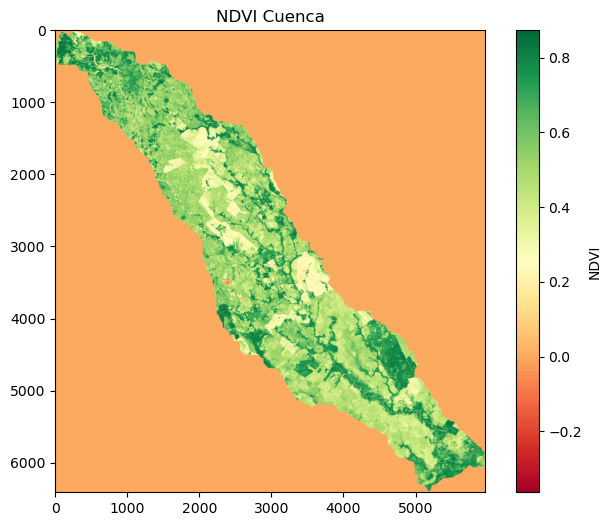

In [47]:
plt.figure(figsize=(8,6))

plt.imshow(ndvi, cmap='RdYlGn')

plt.colorbar(label='NDVI')

plt.title('NDVI Cuenca')

plt.show()


In [48]:
# escalas espaciales
scales = [2,4,8,16,32,64, 128]

# momentos q
qs = np.linspace(-2,2,21)

tau_q = []

In [49]:
for q in qs:
    
    z_eps = []
    eps = []
    
    for s in scales:
        
        rows = ndvi.shape[0] // s
        cols = ndvi.shape[1] // s
        
        if rows < 2 or cols < 2:
            continue
        
        mus = []
        
        # recorrer bloques
        for i in range(rows):
            
            for j in range(cols):
                
                block = ndvi[
                    i*s:(i+1)*s,
                    j*s:(j+1)*s
                ]
                
                mu = np.sum(block)
                
                if mu > 0:
                    mus.append(mu)
        
        mus = np.array(mus)
        
        # funcion de particion
        Zq = np.sum(mus**q)
        
        z_eps.append(np.log(Zq))
        
        eps.append(np.log(s))
    
    # ajuste lineal
    slope, intercept, r, p, std = linregress(
        eps,
        z_eps
    )
    
    tau_q.append(slope)

tau_q = np.array(tau_q)

In [50]:
tau_smooth = tau_q

#savgol_filter(tau_q,7,2)

In [51]:
alpha = np.gradient(
    tau_smooth,
    qs
)

f_alpha = qs * alpha - tau_smooth

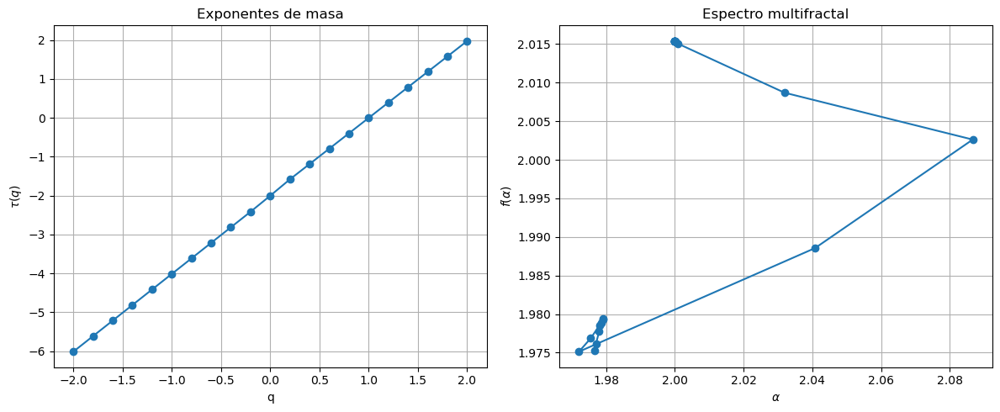

In [52]:
fig, ax = plt.subplots(
    1,
    2,
    figsize=(12,5)
)

# --------------------------------
# EXPONENTES DE MASA
# --------------------------------
ax[0].plot(
    qs,
    tau_smooth,
    'o-'
)

ax[0].set_title(
    'Exponentes de masa'
)

ax[0].set_xlabel('q')

ax[0].set_ylabel(r'$\tau(q)$')

ax[0].grid(True)

# --------------------------------
# ESPECTRO MULTIFRACTAL
# --------------------------------
ax[1].plot(
    alpha,
    f_alpha,
    'o-'
)

ax[1].set_title(
    'Espectro multifractal'
)

ax[1].set_xlabel(r'$\alpha$')

ax[1].set_ylabel(r'$f(\alpha)$')

ax[1].grid(True)

plt.tight_layout()

plt.show()



In [53]:
delta_alpha = (
    np.max(alpha) -
    np.min(alpha)
)

print(
    f'Amplitud multifractal Δα = {delta_alpha:.3f}')

Amplitud multifractal Δα = 0.115


El análisis multifractal espacial del NDVI evidenció una amplitud de singularidades de Δα≈0.115, indicando un comportamiento multifractal débil a moderado. Este resultado sugiere la existencia de heterogeneidad espacial en la cobertura vegetal y en la organización ecológica del paisaje. La multifractalidad observada refleja la presencia de diferentes patrones espaciales asociados a variaciones topográficas, climáticas y de cobertura vegetal dentro de la cuenca. En comparación con la precipitación, el NDVI presenta una menor amplitud multifractal, lo cual es consistente con el carácter integrador y más estable de la respuesta ecosistémica frente a la variabilidad climática.